![Banner](../images/03_08_banner_spatial_analysis_capstone.png)

# Landslide Susceptibility of the Central and Southern Rocky Mountains and Western Great Plains


This is Capstone 4 of the spatial analysis module (Part 7). It maps where landslides are most likely across Colorado, Wyoming, New Mexico and Kansas, at 1 km, using the Ahmed et al. (2017) covariate grid and the USGS landslide inventory (Belair et al. 2025).

**Data:** `data/Great_plain`. The inventory is fetched with `download_data.py great_plains`.

**Study area:** about 1,050,000 km² at 1 km.

**Library:** `geolattice.spatial_analysis`


## Overview

Landslides occur in every U.S. state, and the four states of this capstone, **Colorado, Wyoming, New Mexico and Kansas**, span the full range of exposure: steep, wildfire-prone mountains in the west and nearly flat plains in the east. A **susceptibility map** answers one question: *where are landslides most likely to occur, given the terrain, climate, soils and vegetation?* It says nothing about when, which makes it a planning tool rather than a warning system.

This capstone builds that map at **1 km** resolution over about 1,050,000 km², using

- the environmental covariate grid assembled for **Ahmed et al. (2017)**, *Assessing soil carbon vulnerability in the Western USA by geospatial modeling of pyrogenic and particulate carbon stocks* (Journal of Geophysical Research: Biogeosciences 122: 354-369). The paper mapped soil carbon fractions over these four states with random forests on terrain, climate, soil, vegetation and fire-regime covariates. The same covariates, grid and random-forest workflow are reused here for a different response: landslide occurrence;
- the **USGS Landslide Inventories across the United States, version 3.0** (Belair et al. 2025), as training and test data.

Three families of model are built and compared, following Module 03: a **bivariate statistical** model (frequency ratio), a **knowledge-driven multi-criteria** model (AHP-weighted fuzzy overlay) and **machine learning** (logistic regression, random forest, gradient boosting).

## Overview

| Stage | Question | Main tools |
|---|---|---|
| **Covariates** | What environmental conditions describe each 1 km cell? | the Ahmed et al. (2017) covariate grid |
| **Inventory** | Where have landslides been recorded, and how complete is the record? | USGS inventory v3, confidence filter, state clip |
| **Sampling design** | Which cells can serve as non-landslide examples? | surveyed-tile background, exclusion buffer |
| **Model 1: frequency ratio** | How much more common are landslides in each class of each factor? | frequency ratio, landslide susceptibility index |
| **Model 2: multi-criteria** | Where do expert rules place high susceptibility? | AHP weights, `large`, `small`, `linear`, `weighted_linear_combination`, `monte_carlo_weights` |
| **Model 3: machine learning** | What does the inventory itself say? | logistic regression, random forest, gradient boosting; spatial cross-validation |
| **Validation** | Which model ranks unseen landslides highest? | success- and prediction-rate curves, AUC, class density |
| **Classes and uncertainty** | How much land is highly susceptible, and how sure are we? | five classes; background-draw spread; weight uncertainty |
| **Inventory gaps** | Where is terrain susceptible but no landslides are recorded? | susceptibility vs inventory coverage |

### What this notebook reuses

| Topic | Notebook |
|---|---|
| Terrain derivatives | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |
| Fuzzy membership and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb), [`03_04_01_03_weighted_suitability.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_01_03_weighted_suitability.ipynb) |
| Weight uncertainty | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| Presence-background modelling and spatial cross-validation | [`03_08_05_habitat_suitability.ipynb`](03_08_05_habitat_suitability.ipynb) |

## Table of Contents

1. [Setup](#setup)
2. [Problem statement and study area](#problem-statement-and-study-area)
3. [The covariate grid](#the-covariate-grid)
4. [The landslide inventory](#the-landslide-inventory)
5. [Sampling design](#sampling-design)
6. [Model 1: frequency ratio](#model-1-frequency-ratio)
7. [Model 2: AHP multi-criteria model](#model-2-ahp-multi-criteria-model)
8. [Model 3: machine learning](#model-3-machine-learning)
9. [What drives susceptibility?](#what-drives-susceptibility)
10. [Validation of all models](#validation-of-all-models)
11. [Susceptibility classes](#susceptibility-classes)
12. [Uncertainty](#uncertainty)
13. [Where the inventory is likely incomplete](#where-the-inventory-is-likely-incomplete)
14. [Outputs](#outputs)
15. [Limitations](#limitations)
16. [Where to go next](#where-to-go-next)

## Setup

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports.
import sys  # make the capstone helper module importable
import time  # report how long the heavier steps take
import warnings  # silence harmless warnings
from pathlib import Path  # filesystem paths

# Third-party numeric / geospatial / plotting stack.
import geopandas as gpd  # state outlines, inventory points, outputs
import matplotlib.pyplot as plt  # maps and charts
import numpy as np  # arrays
import pandas as pd  # tables
from IPython.display import display  # rich table previews
from scipy import ndimage  # exclusion buffers

# Machine learning (scikit-learn).
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Shared capstone helpers live next to this notebook.
sys.path.insert(0, str(Path.cwd()))
import data_processing as dp  # paths and helpers

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    ROOT = dp.find_repo_root()

# GeoLattice tools.
from geolattice.raster import write_raster_data
from geolattice.spatial_analysis import (
    jaccard_index,  # overlap of two top-class masks
    large,  # sigmoid membership, large values -> 1
    linear,  # linear ramp membership
    monte_carlo_weights,  # Dirichlet weight uncertainty
    small,  # sigmoid membership, small values -> 1
    weighted_linear_combination,  # weighted linear combination
)
from geolattice.viz import apply_map_style

apply_map_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
RNG = np.random.default_rng(2017)  # one seed for every random step

SRC = ROOT / "Data" / "03_spatial_analysis" / "Great_plain"
INVENTORY = SRC / "landslides" / "us_landslides_v3_great_plains.csv"
OUT = dp.capstone_dir(ROOT, "great_plains_landslides")
print(f"Inputs:  {SRC}")
print(f"Outputs: {OUT}")

Inputs:  /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/Great_plain
Outputs: /home/zia207/Github/GeoLattice/Data/03_spatial_analysis/capstone_spatial_analysis/great_plains_landslides


## Problem statement and study area

**Study area.** Colorado, Kansas, New Mexico and Wyoming, the study region of Ahmed et al. (2017). Elevation rises from about 200 m in eastern Kansas to more than 4,300 m in the Colorado Rockies. Mean annual precipitation ranges from under 150 mm in the New Mexico basins to over 2,000 mm on the highest ranges.

**Landslides in the region** are of several kinds: deep-seated slides and earthflows in weak shales of the Colorado Plateau and the Wyoming basins, rockfall and debris flows in the high mountains, and **post-wildfire debris flows**, which have become a leading hazard in Colorado and New Mexico. This last link to fire is why the fire-regime layer of the soil carbon study is useful here.

**Question.** Which parts of the four states are most susceptible to landslides, which environmental factors explain the pattern, and how far can a national inventory compiled from many sources be trusted to say so?

## The covariate grid

`gp_grid_new.csv` holds the covariates of Ahmed et al. (2017) at the nodes of a **1 km grid** in USA Contiguous Albers Equal Area (NAD83). The terrain layers were derived from the 30 m National Elevation Dataset resampled to 90 m, so each node carries the 90 m value at that point, not a 1 km average.

| Column | Variable | Source in the paper |
|---|---|---|
| `elev` | Elevation (m) | NED |
| `slope_g` | Slope gradient (degrees) | NED |
| `slopeleng` | Slope length (m) | NED |
| `aspect` | Aspect (degrees; -1 = flat) | NED |
| `tpi_2000` | Topographic position index, 2,000 m window (m) | NED |
| `topo_2000` | Slope position: 1 canyon bottom, 2 gentle slope, 3 steep slope, 4 ridgeline | from TPI and slope |
| `h_curvatur`, `v_curvatur` | Horizontal (plan) and vertical (profile) curvature | NED |
| `ndvi` | Mean June-July NDVI, 2000-2011 | MODIS MOD13Q1 |
| `preci`, `temp` | Mean annual precipitation (mm), temperature (°C) | PRISM |
| `silt_clay` | Silt + clay in surface soil (%) | SSURGO / STATSGO |
| `kfactor` | Soil erodibility factor | SSURGO / STATSGO |
| `nlcd` | Land cover: 3 barren, 4 forest, 5 shrubland, 6 herbaceous, 7 planted/cultivated | NLCD 2006 |
| `frg` | LANDFIRE fire regime group | LANDFIRE |

The grid covers the vegetated land of the paper's prediction domain: water, developed land and wetlands were excluded, and they are excluded here too.

In [2]:
t0 = time.time()
grid = pd.read_csv(SRC / "gp_grid_new.csv")
print(f"Grid nodes: {len(grid):,} read in {time.time() - t0:.0f} s")

# Lookup tables shipped with the data.
frg_names = pd.read_csv(SRC / "Frg_ID.csv").set_index("frg_id")["frg"].to_dict()
slope_pos_names = pd.read_csv(SRC / "slope_pos_id.csv").set_index("sp_id")["slope_position"].to_dict()
nlcd_names = {3: "Barren", 4: "Forest", 5: "Shrubland", 6: "Herbaceous", 7: "Planted/Cultivated"}

# Index every node on a regular 1 km raster.
CELL = 1000.0
XMIN, YMAX = grid.x.min() - CELL / 2, grid.y.max() + CELL / 2  # outer edges; x, y are cell centres
grid["col"] = ((grid.x - grid.x.min()) / CELL).round().astype(int)
grid["row"] = ((grid.y.max() - grid.y) / CELL).round().astype(int)
NR, NC = grid.row.max() + 1, grid.col.max() + 1
GT = (XMIN, CELL, 0.0, YMAX, 0.0, -CELL)
EXTENT = (XMIN, XMIN + NC * CELL, YMAX - NR * CELL, YMAX)

states = gpd.read_file(SRC / "GP_STATE.shp")
CRS = states.crs  # USA Contiguous Albers Equal Area (NAD83)
print(f"Raster: {NC} x {NR} cells of {CELL / 1000:.0f} km; CRS: {CRS.name}")


def to_raster(values, dtype=float):
    """Place one value per grid node on the 1 km raster (NaN elsewhere)."""
    out = np.full((NR, NC), np.nan)
    out[grid.row.values, grid.col.values] = np.asarray(values, dtype=float)
    return out


def show(ax, values, title, cmap="viridis", **kw):
    """Map one node-level variable with the state outlines."""
    im = ax.imshow(to_raster(values), cmap=cmap, extent=EXTENT, interpolation="nearest", **kw)
    states.boundary.plot(ax=ax, color="black", linewidth=0.6)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return im


# Which state is each node in?
nodes = gpd.GeoDataFrame(grid[["row", "col"]], geometry=gpd.points_from_xy(grid.x, grid.y), crs=CRS)
grid["state"] = gpd.sjoin(nodes, states[["STATE", "geometry"]], how="left", predicate="within")["STATE"].values
print(grid.state.value_counts(dropna=False).to_string())

Grid nodes: 1,009,414 read in 1 s
Raster: 1372 x 1547 cells of 1 km; CRS: Albers_Conical_Equal_Area


state
New Mexico    309557
Colorado      256608
Wyoming       244670
Kansas        198420
NaN              159


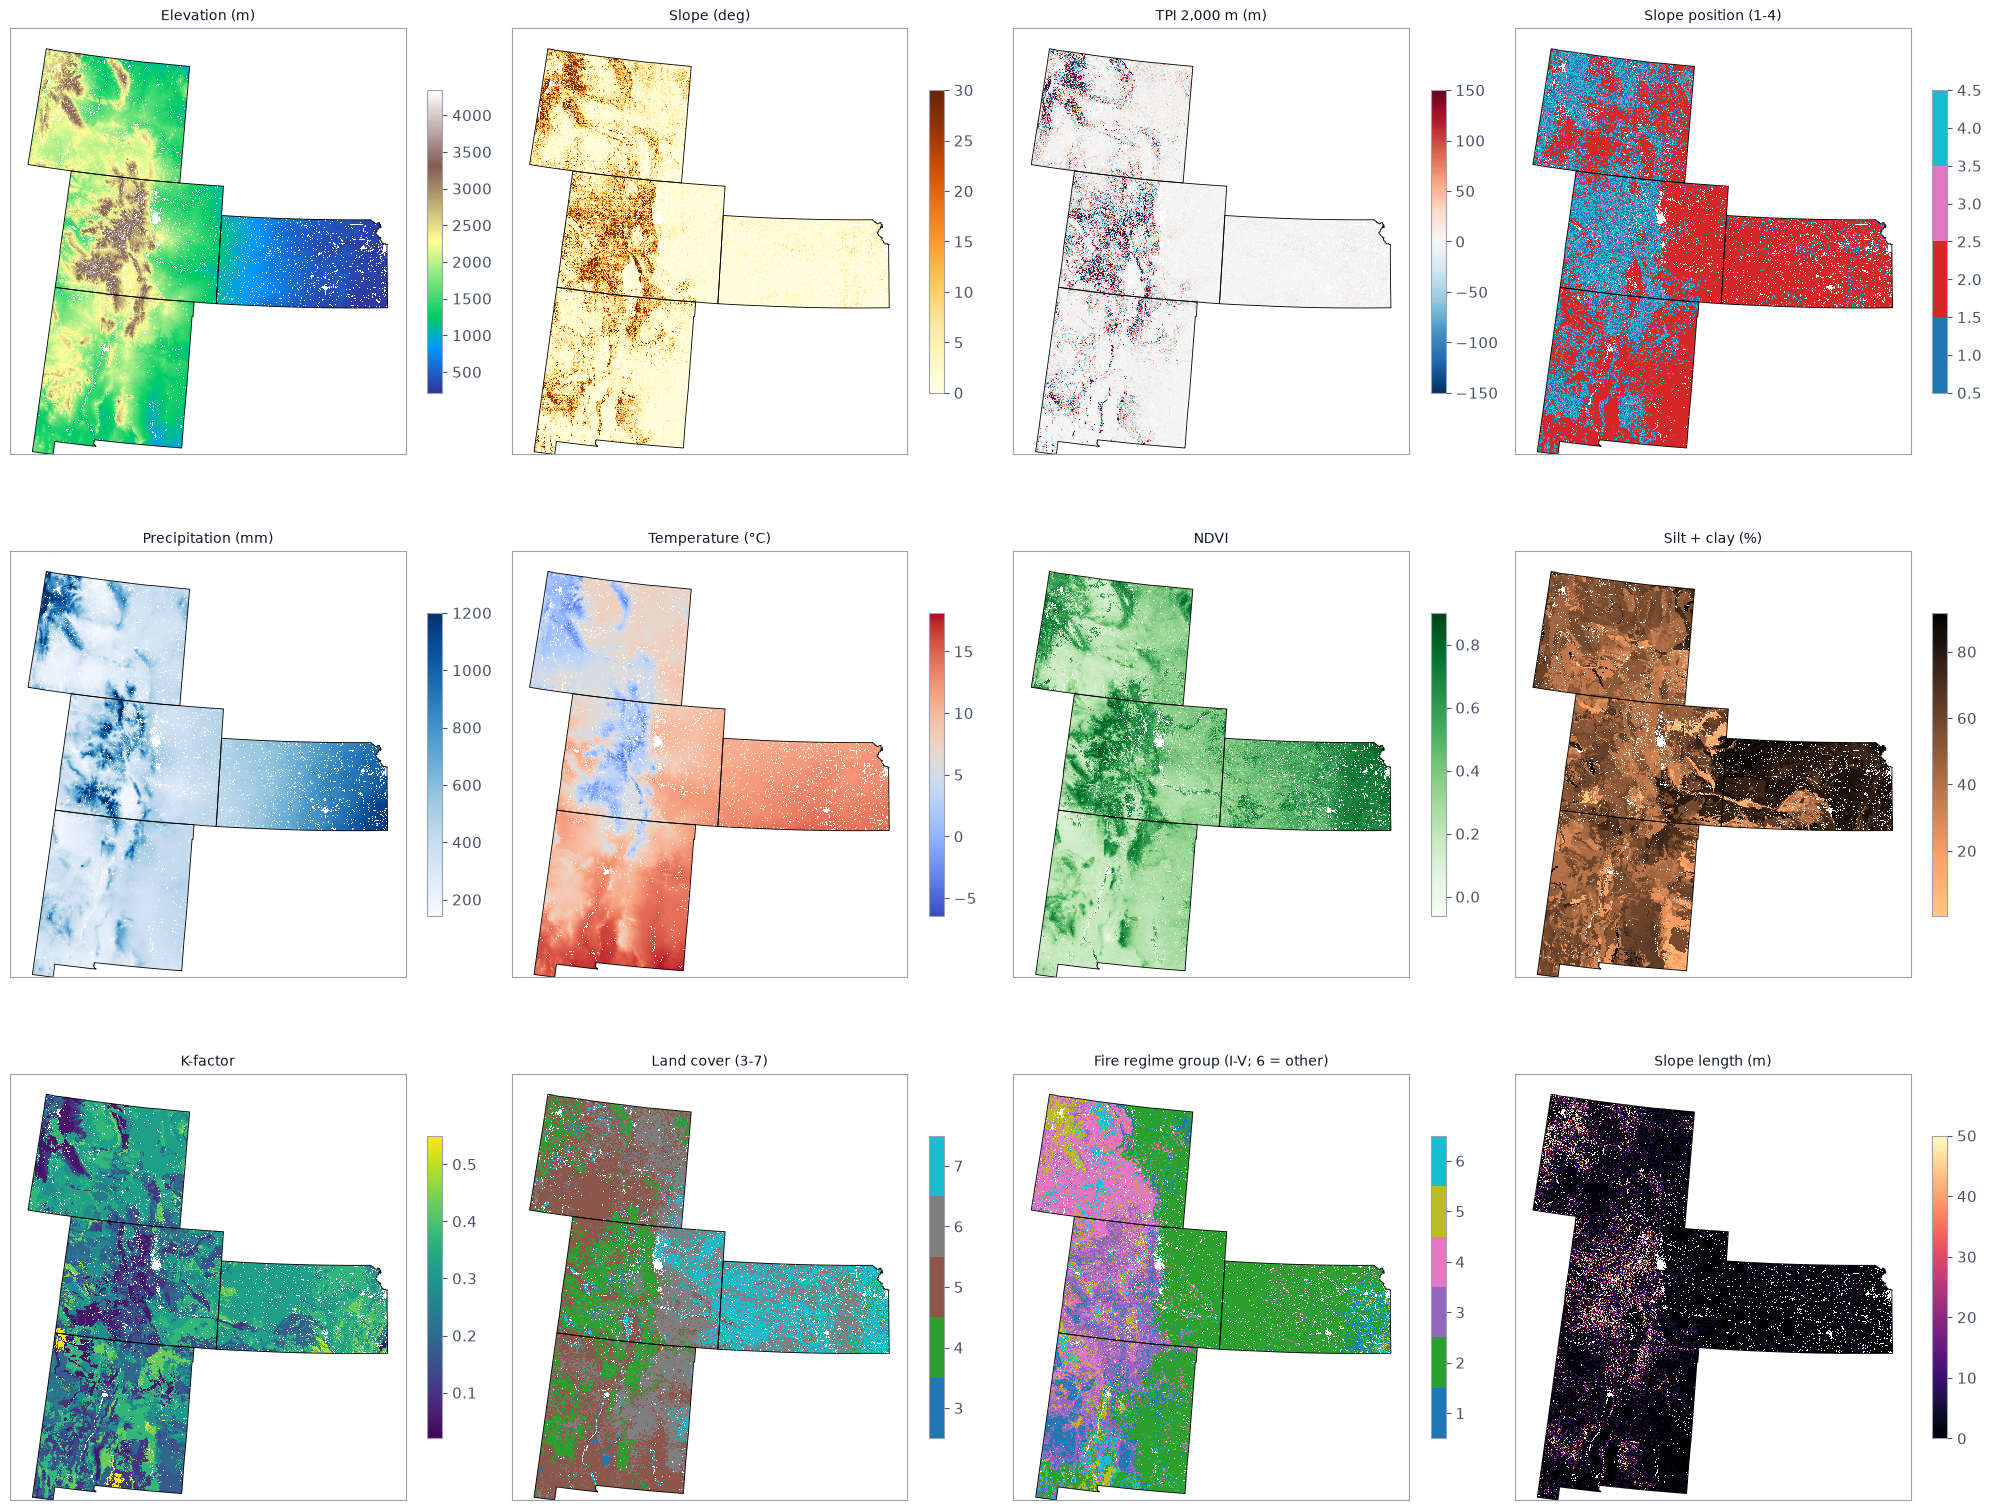

In [3]:
panels = [("elev", "Elevation (m)", "terrain", {}), ("slope_g", "Slope (deg)", "YlOrBr", dict(vmax=30)),
          ("tpi_2000", "TPI 2,000 m (m)", "RdBu_r", dict(vmin=-150, vmax=150)),
          ("topo_2000", "Slope position (1-4)", plt.get_cmap("tab10", 4), dict(vmin=0.5, vmax=4.5)),
          ("preci", "Precipitation (mm)", "Blues", dict(vmax=1200)), ("temp", "Temperature (°C)", "coolwarm", {}),
          ("ndvi", "NDVI", "Greens", {}), ("silt_clay", "Silt + clay (%)", "copper_r", {}),
          ("kfactor", "K-factor", "viridis", {}), ("nlcd", "Land cover (3-7)", plt.get_cmap("tab10", 5), dict(vmin=2.5, vmax=7.5)),
          ("frg", "Fire regime group (I-V; 6 = other)", plt.get_cmap("tab10", 6), dict(vmin=0.5, vmax=6.5)), ("slopeleng", "Slope length (m)", "magma", dict(vmax=50))]
frg_plot = grid.frg.where(grid.frg <= 5, 6)  # non-fire classes shown together
fig, axes = plt.subplots(3, 4, figsize=(20, 16))
for ax, (col, title, cmap, kw) in zip(axes.ravel(), panels):
    im = show(ax, frg_plot if col == "frg" else grid[col], title, cmap, **kw)
    plt.colorbar(im, ax=ax, fraction=0.035)
plt.tight_layout()
plt.show()

## The landslide inventory

The USGS compilation brings together inventories from state geological surveys, the USGS, universities and other agencies. Each record carries a **Confidence** code:

| Code | Meaning |
|---|---|
| 1 | Possible landslide in the area |
| 2 | Probable landslide in the area |
| 3 | Likely landslide at or near this location |
| 5 | Moderate confidence in the extent or nature of the landslide |
| 8 | High confidence in the extent or nature of the landslide |

Codes 1 and 2 locate a landslide only to "the area", often a whole quadrangle or a report region, which is too vague for a 1 km model. Training uses **Confidence ≥ 3**. All records, including codes 1 and 2, are still used in Section 5 to decide where the region has been surveyed at all.

> The inventory is not shipped with the repository. Run `python Tutorials/notebooks/03_spatial_analysis/03_07_capston/download_data.py great_plains` once; it writes `Data/03_spatial_analysis/Great_plain/landslides/us_landslides_v3_great_plains.csv`.

In [4]:
if not INVENTORY.exists():
    raise FileNotFoundError(
        f"Landslide inventory not found: {INVENTORY.relative_to(ROOT)}\n"
        "Run:  python Tutorials/notebooks/03_spatial_analysis/03_07_capston/download_data.py great_plains"
    )
inv = pd.read_csv(INVENTORY, low_memory=False)
conf_col = next(c for c in inv.columns if c.lower() == "confidence")
src_col = next((c for c in inv.columns if c.lower() == "inventory"), None)
inv["confidence"] = pd.to_numeric(inv[conf_col], errors="coerce")

# Project to the grid CRS and keep records inside the four states.
pts = gpd.GeoDataFrame(inv, geometry=gpd.points_from_xy(inv.longitude, inv.latitude), crs="EPSG:4326").to_crs(CRS)
pts = gpd.sjoin(pts, states[["STATE", "geometry"]], how="inner", predicate="within").drop(columns="index_right")
pts["col"] = np.floor((pts.geometry.x - XMIN) / CELL).astype(int)
pts["row"] = np.floor((YMAX - pts.geometry.y) / CELL).astype(int)
print(f"Records inside the four states: {len(pts):,}")

summary = pd.crosstab(pts.STATE, pts.confidence, margins=True, margins_name="total")
display(summary)
if src_col:
    top_src = pts[src_col].value_counts().head(12).rename("records")
    display(top_src.to_frame())

Records inside the four states: 69,031


confidence,1,2,3,5,8,total
STATE,,,,,,
Colorado,10064,18618,137,11,2895,31725
Kansas,0,4,0,0,0,4
New Mexico,1,15,3435,12,0,3463
Wyoming,4,41,49,33744,1,33839
total,10069,18678,3621,33767,2896,69031


,records
Inventory,
WY WSGS,33741
CO GS,28517
USGS Conterminous,3445
USGS CO Front Range Sept 2013,1350
USGS CO Front Range July 1999,806
"Western CO (Regmi and others, 2010)",734
NASA,239
UT GRC,111
USGS Post-Fire Debris Flows,70


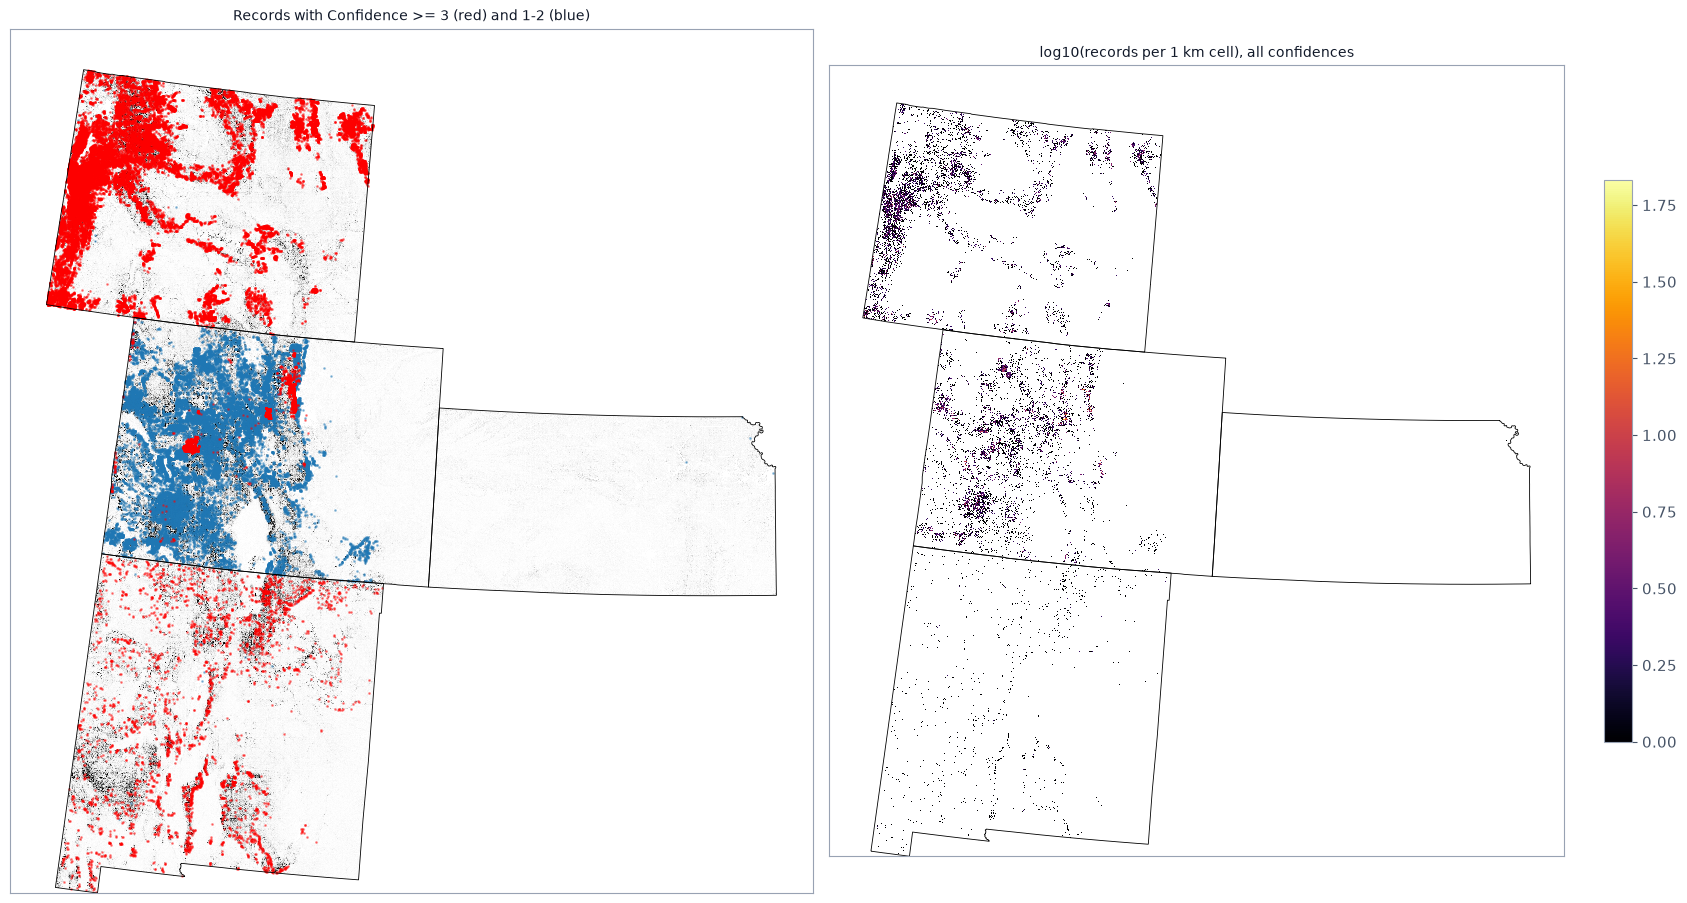

,cells,landslide_cells,landslide_cells_per_1000_km2
state,,,
Colorado,256608,780,3.040
Kansas,198420,0,0.000
New Mexico,309557,3256,10.518
Wyoming,244670,19708,80.549


In [5]:
# Cells with at least one record, before and after the confidence filter.
cell_id = grid.row.values * NC + grid.col.values
node_of_cell = pd.Series(np.arange(len(grid)), index=cell_id)


def node_hits(df):
    ids = (df.row * NC + df.col).values
    ids = ids[np.isin(ids, node_of_cell.index)]
    return np.bincount(node_of_cell.loc[ids].values, minlength=len(grid))


grid["n_all"] = node_hits(pts)
grid["n_conf3"] = node_hits(pts[pts.confidence >= 3])
grid["landslide"] = (grid.n_conf3 > 0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(17, 9))
show(axes[0], grid.slope_g, "Records with Confidence >= 3 (red) and 1-2 (blue)", "Greys", vmax=40)
low = pts[pts.confidence < 3]
high = pts[pts.confidence >= 3]
axes[0].scatter(low.geometry.x, low.geometry.y, s=1, c="tab:blue", alpha=0.4)
axes[0].scatter(high.geometry.x, high.geometry.y, s=1, c="red", alpha=0.4)
dens = np.where(grid.n_all > 0, np.log10(grid.n_all), np.nan)
im = show(axes[1], dens, "log10(records per 1 km cell), all confidences", "inferno")
plt.colorbar(im, ax=axes[1], fraction=0.035)
plt.tight_layout()
plt.show()

by_state = grid.groupby("state").agg(cells=("landslide", "size"), landslide_cells=("landslide", "sum"))
by_state["landslide_cells_per_1000_km2"] = 1000 * by_state.landslide_cells / by_state.cells
display(by_state)

**Reading the inventory.** Compare the density of landslide cells between the states with what their terrain would suggest. In a national compilation, each state's share reflects which surveys were digitised and contributed as much as how many landslides occurred, so blank areas mix true absence of landslides with absence of mapping. This is the most important property of the training data, and Section 5 is designed around it.

## Sampling design

A susceptibility model learns by comparing **landslide cells** with **non-landslide cells**. Where nobody looked, a cell without a record is not evidence of stability, and sampling it as a negative teaches the model that unsurveyed terrain is safe. Three rules reduce that bias:

1. **Surveyed tiles only.** The region is divided into 50 km tiles. Negatives are drawn only from tiles that contain at least one inventory record of *any* confidence, a simple form of the target-group background used in species distribution modelling.
2. **Exclusion buffer.** Cells within 2 km of a landslide cell are not used as negatives, because records are positioned only to within a few hundred metres and landslide clusters extend beyond mapped points.
3. **Several draws.** Five independent negative samples, each twice the number of landslide cells, are drawn; models are fitted to each and averaged.

Landslide cells (Confidence >= 3): 23,744
Surveyed tiles: 307 of 480 (66% of the grid)
Negative pool: 540,185 cells; 5 draws of 47,488


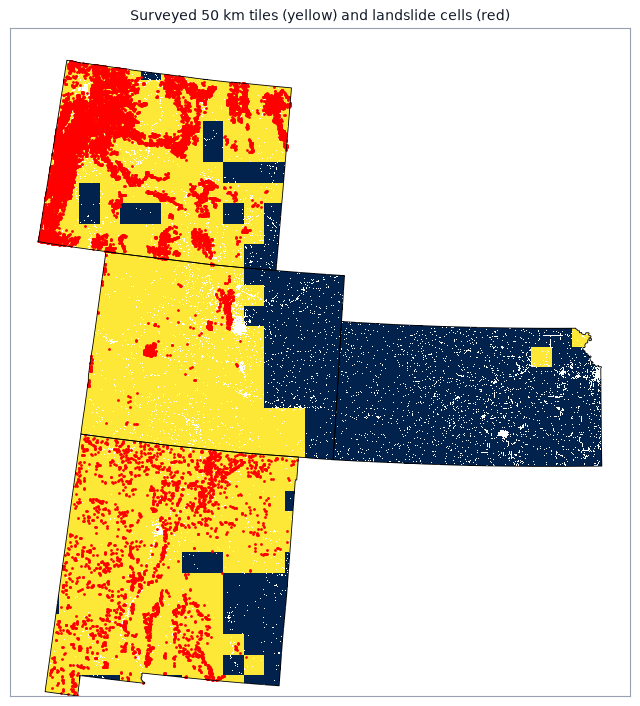

In [6]:
TILE = 50_000.0
grid["tile"] = (np.floor((grid.x - grid.x.min()) / TILE).astype(int) * 1000
                + np.floor((grid.y - grid.y.min()) / TILE).astype(int))
surveyed_tiles = set(grid.loc[grid.n_all > 0, "tile"])
grid["surveyed"] = grid.tile.isin(surveyed_tiles)

ls_ras = to_raster(grid.landslide) == 1
buffer = ndimage.binary_dilation(ls_ras, structure=np.ones((5, 5)))  # 2 cells either side = 2 km
grid["near_landslide"] = buffer[grid.row.values, grid.col.values] & (grid.landslide == 0)

pres_idx = np.flatnonzero(grid.landslide.values == 1)
neg_pool = np.flatnonzero(grid.surveyed.values & (grid.landslide.values == 0) & ~grid.near_landslide.values)
N_DRAWS = 5
neg_draws = [RNG.choice(neg_pool, size=min(2 * len(pres_idx), len(neg_pool)), replace=False) for _ in range(N_DRAWS)]

print(f"Landslide cells (Confidence >= 3): {len(pres_idx):,}")
print(f"Surveyed tiles: {len(surveyed_tiles)} of {grid.tile.nunique()} "
      f"({grid.surveyed.mean():.0%} of the grid)")
print(f"Negative pool: {len(neg_pool):,} cells; {N_DRAWS} draws of {len(neg_draws[0]):,}")

fig, ax = plt.subplots(figsize=(8, 9))
show(ax, grid.surveyed.astype(float), "Surveyed 50 km tiles (yellow) and landslide cells (red)", "cividis")
ax.scatter(grid.x.values[pres_idx], grid.y.values[pres_idx], s=1, c="red")
plt.show()

# Spatial cross-validation groups: 100 km blocks.
BLOCK = 100_000.0
grid["block"] = (np.floor((grid.x - grid.x.min()) / BLOCK).astype(int) * 1000
                 + np.floor((grid.y - grid.y.min()) / BLOCK).astype(int))
N_FOLDS = 5

## Model 1: frequency ratio

The **frequency ratio** (FR) of a factor class is the share of landslide cells that fall in the class divided by the share of area it covers:

$$
FR_{ij} = \frac{N_{ij}^{ls} / N^{ls}}{N_{ij} / N}
$$

$FR > 1$ means landslides are more common than average in the class. The **landslide susceptibility index** of a cell is the sum of the log frequency ratios of its classes across all factors, $LSI = \sum_i \ln FR_{ij}$. The method is transparent, needs no model fitting, and is a standard baseline in landslide studies.

Continuous factors are split into deciles; categorical factors use their classes. Frequency ratios are computed on **surveyed tiles only**, for the reason given in Section 5.

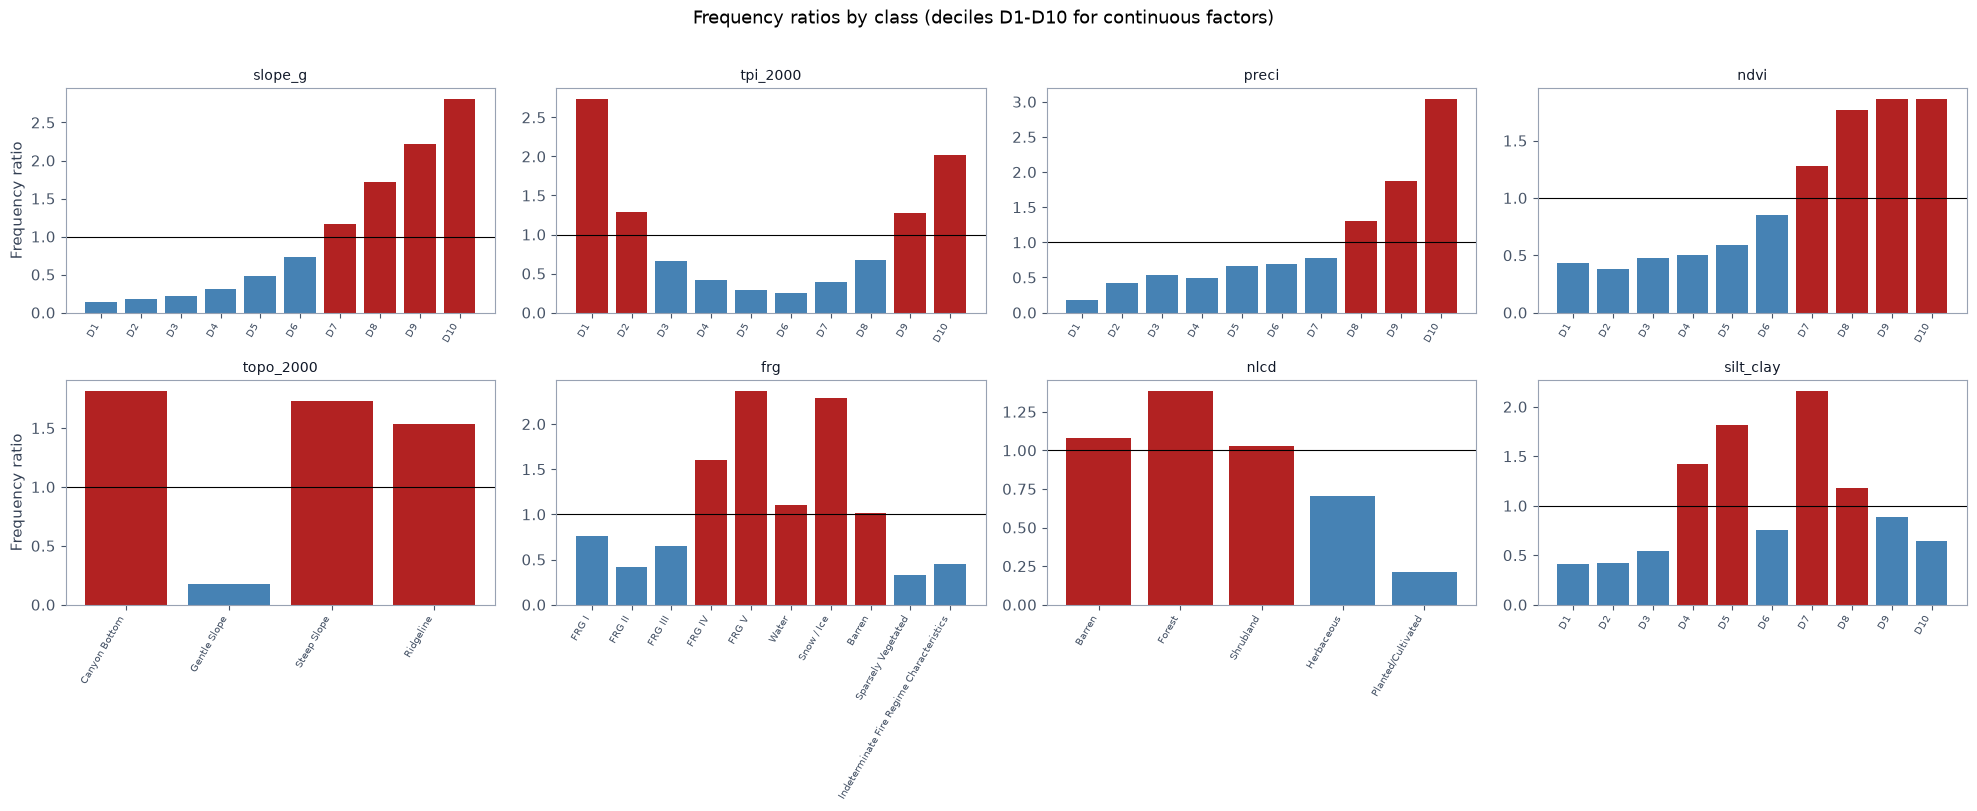

In [7]:
FR_CONT = ["slope_g", "tpi_2000", "elev", "preci", "temp", "ndvi", "silt_clay", "kfactor", "v_curvatur", "h_curvatur"]
FR_CAT = ["topo_2000", "nlcd", "frg"]


def fr_classes(df):
    """Class label of every node for every factor (deciles for continuous factors)."""
    cls = {}
    for f in FR_CONT:
        edges = np.unique(np.nanquantile(grid.loc[grid.surveyed, f], np.linspace(0, 1, 11)))
        cls[f] = np.clip(np.searchsorted(edges, df[f].values, side="right") - 1, 0, len(edges) - 2)
    for f in FR_CAT:
        cls[f] = df[f].values.astype(int)
    return cls


CLS = fr_classes(grid)


def fr_tables(train_mask):
    """Frequency-ratio table for every factor, from the nodes in ``train_mask`` (surveyed only)."""
    m = train_mask & grid.surveyed.values
    y = grid.landslide.values[m]
    tabs = {}
    for f, c in CLS.items():
        cm = c[m]
        classes = np.unique(c)
        area = np.array([(cm == k).sum() for k in classes], float)
        lsn = np.array([y[cm == k].sum() for k in classes], float)
        fr = ((lsn + 0.5) / (y.sum() + 0.5)) / ((area + 1) / m.sum())  # small offsets avoid log(0)
        tabs[f] = pd.Series(fr, index=classes)
    return tabs


def lsi(tabs, idx=slice(None)):
    """Landslide susceptibility index (sum of log FR) for the nodes in ``idx``."""
    return sum(np.log(tabs[f].reindex(CLS[f][idx]).fillna(1.0).values) for f in tabs)


fr_all = fr_tables(np.ones(len(grid), bool))
grid["fr_lsi"] = lsi(fr_all)

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, f in zip(axes.ravel(), ["slope_g", "tpi_2000", "preci", "ndvi", "topo_2000", "frg", "nlcd", "silt_clay"]):
    t = fr_all[f]
    if f == "topo_2000":
        labels = [slope_pos_names.get(k, k) for k in t.index]
    elif f == "frg":
        labels = [str(frg_names.get(k, k)).replace("Fire Regime Group ", "FRG ") for k in t.index]
    elif f == "nlcd":
        labels = [nlcd_names.get(k, k) for k in t.index]
    else:
        labels = [f"D{k + 1}" for k in t.index]
    ax.bar(range(len(t)), t.values, color=np.where(t.values > 1, "firebrick", "steelblue"))
    ax.axhline(1, color="black", lw=0.8)
    ax.set_xticks(range(len(t)), labels, rotation=60, ha="right", fontsize=7)
    ax.set_title(f, fontsize=10)
axes[0, 0].set_ylabel("Frequency ratio")
axes[1, 0].set_ylabel("Frequency ratio")
plt.suptitle("Frequency ratios by class (deciles D1-D10 for continuous factors)", y=1.01)
plt.tight_layout()
plt.show()

**Reading the frequency ratios.** Bars above 1 (red) mark classes where landslides are more common than average. Three things to check:

- Does the ratio rise steadily through the slope deciles? A clean monotonic rise means slope is behaving as the dominant control.
- Do steep slopes and canyon bottoms sit above 1 and gentle slopes below?
- Precipitation, NDVI, fire regime and land cover often show strong ratios too. In this region the wet, green, fire-prone land *is* the mountains, so these bars can repeat the terrain signal through other variables. A bivariate method cannot separate such overlapping effects; Model 3 can.

## Model 2: AHP multi-criteria model

A knowledge-driven model encodes what geomorphology says controls slope stability, without fitting it to the inventory. Seven criteria are used:

| Criterion | Membership | Reasoning |
|---|---|---|
| Slope | `large`, midpoint 15°, spread 4 | Shear stress rises with slope; most slides start on slopes above 15° |
| Local relief | `large` on \|TPI 2,000 m\|, midpoint 60 m, spread 3 | Relief supplies the height a slide needs |
| Slope position | steep slope 1.0, canyon bottom 0.6, ridgeline 0.5, gentle slope 0.1 | Steep side-slopes fail; canyon bottoms receive debris flows |
| Precipitation | `linear`, 250 to 900 mm | Wetter slopes reach failure pore pressures more often |
| Fire regime | FRG IV 1.0, FRG III 0.7, barren 0.7, FRG V 0.6, FRG I 0.5, FRG II 0.4 | Stand-replacing fire in forest (FRG IV) strips the canopy and triggers debris flows; FRG II is mostly grassland, where frequent fire does far less to slope stability |
| Vegetation (NDVI) | `small`, midpoint 0.35, spread 4 | Roots reinforce soil; sparse cover means weaker slopes |
| Silt + clay | `linear`, 20 to 80 % | Fine-grained soils lose strength when wet |

A weighted linear combination is **compensatory**: a flat, wet, clay-rich field in eastern Kansas collects points for precipitation and soil and can score as high as a dry mountain slope, although flat land cannot slide. The combined score is therefore multiplied by a **slope gate** that is 0 below 2°, rises linearly to 1 at 8°, and leaves steeper land unchanged. This is the hybrid "constraint × score" design of Module 03.04.

Weights come from the **Analytic Hierarchy Process** (AHP; Saaty 1980). Each pair of criteria is judged on the 1-9 scale ("slope is moderately more important than precipitation" = 3); the weights are the principal eigenvector of the comparison matrix, and the **consistency ratio** (CR) checks that the judgments do not contradict each other. CR < 0.10 is the usual acceptance threshold.

GeoLattice has no AHP function, so a short one is written here.

In [8]:
CRITERIA = ["slope", "relief", "slope_position", "precipitation", "fire_regime", "vegetation", "silt_clay"]
# Upper-triangle judgments: (row criterion, column criterion) -> how much more important row is.
JUDGMENTS = {
    ("slope", "relief"): 2, ("slope", "slope_position"): 3, ("slope", "precipitation"): 3, ("slope", "fire_regime"): 4,
    ("slope", "vegetation"): 5, ("slope", "silt_clay"): 5,
    ("relief", "slope_position"): 2, ("relief", "precipitation"): 2, ("relief", "fire_regime"): 3,
    ("relief", "vegetation"): 4, ("relief", "silt_clay"): 4,
    ("slope_position", "precipitation"): 1, ("slope_position", "fire_regime"): 2, ("slope_position", "vegetation"): 3,
    ("slope_position", "silt_clay"): 3,
    ("precipitation", "fire_regime"): 2, ("precipitation", "vegetation"): 3, ("precipitation", "silt_clay"): 3,
    ("fire_regime", "vegetation"): 2, ("fire_regime", "silt_clay"): 2,
    ("vegetation", "silt_clay"): 1,
}
RANDOM_INDEX = {1: 0.0, 2: 0.0, 3: 0.58, 4: 0.90, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41, 9: 1.45, 10: 1.49}


def ahp(criteria, judgments):
    """AHP weights (principal eigenvector) and consistency ratio for a reciprocal matrix."""
    n = len(criteria)
    A = np.ones((n, n))
    for (a, b), v in judgments.items():
        i, j = criteria.index(a), criteria.index(b)
        A[i, j], A[j, i] = v, 1.0 / v
    vals, vecs = np.linalg.eig(A)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    w = w / w.sum()
    ci = (vals[k].real - n) / (n - 1)
    return pd.Series(w, index=criteria), A, ci / RANDOM_INDEX[n]


W_AHP, A_MATRIX, CR = ahp(CRITERIA, JUDGMENTS)
display(pd.DataFrame(A_MATRIX, index=CRITERIA, columns=CRITERIA).round(2))
display(W_AHP.rename("weight").to_frame())
print(f"Consistency ratio: {CR:.3f} ({'acceptable' if CR < 0.10 else 'revise the judgments'})")

,slope,relief,slope_position,precipitation,fire_regime,vegetation,silt_clay
slope,1.00,2.00,3.00,3.00,4.0,5.0,5.0
relief,0.50,1.00,2.00,2.00,3.0,4.0,4.0
slope_position,0.33,0.50,1.00,1.00,2.0,3.0,3.0
precipitation,0.33,0.50,1.00,1.00,2.0,3.0,3.0
fire_regime,0.25,0.33,0.50,0.50,1.0,2.0,2.0
vegetation,0.20,0.25,0.33,0.33,0.5,1.0,1.0
silt_clay,0.20,0.25,0.33,0.33,0.5,1.0,1.0


,weight
slope,0.336
relief,0.219
slope_position,0.133
precipitation,0.133
fire_regime,0.080
vegetation,0.049
silt_clay,0.049


Consistency ratio: 0.011 (acceptable)


Share of cells closed by the slope gate (< 2 deg): 44%


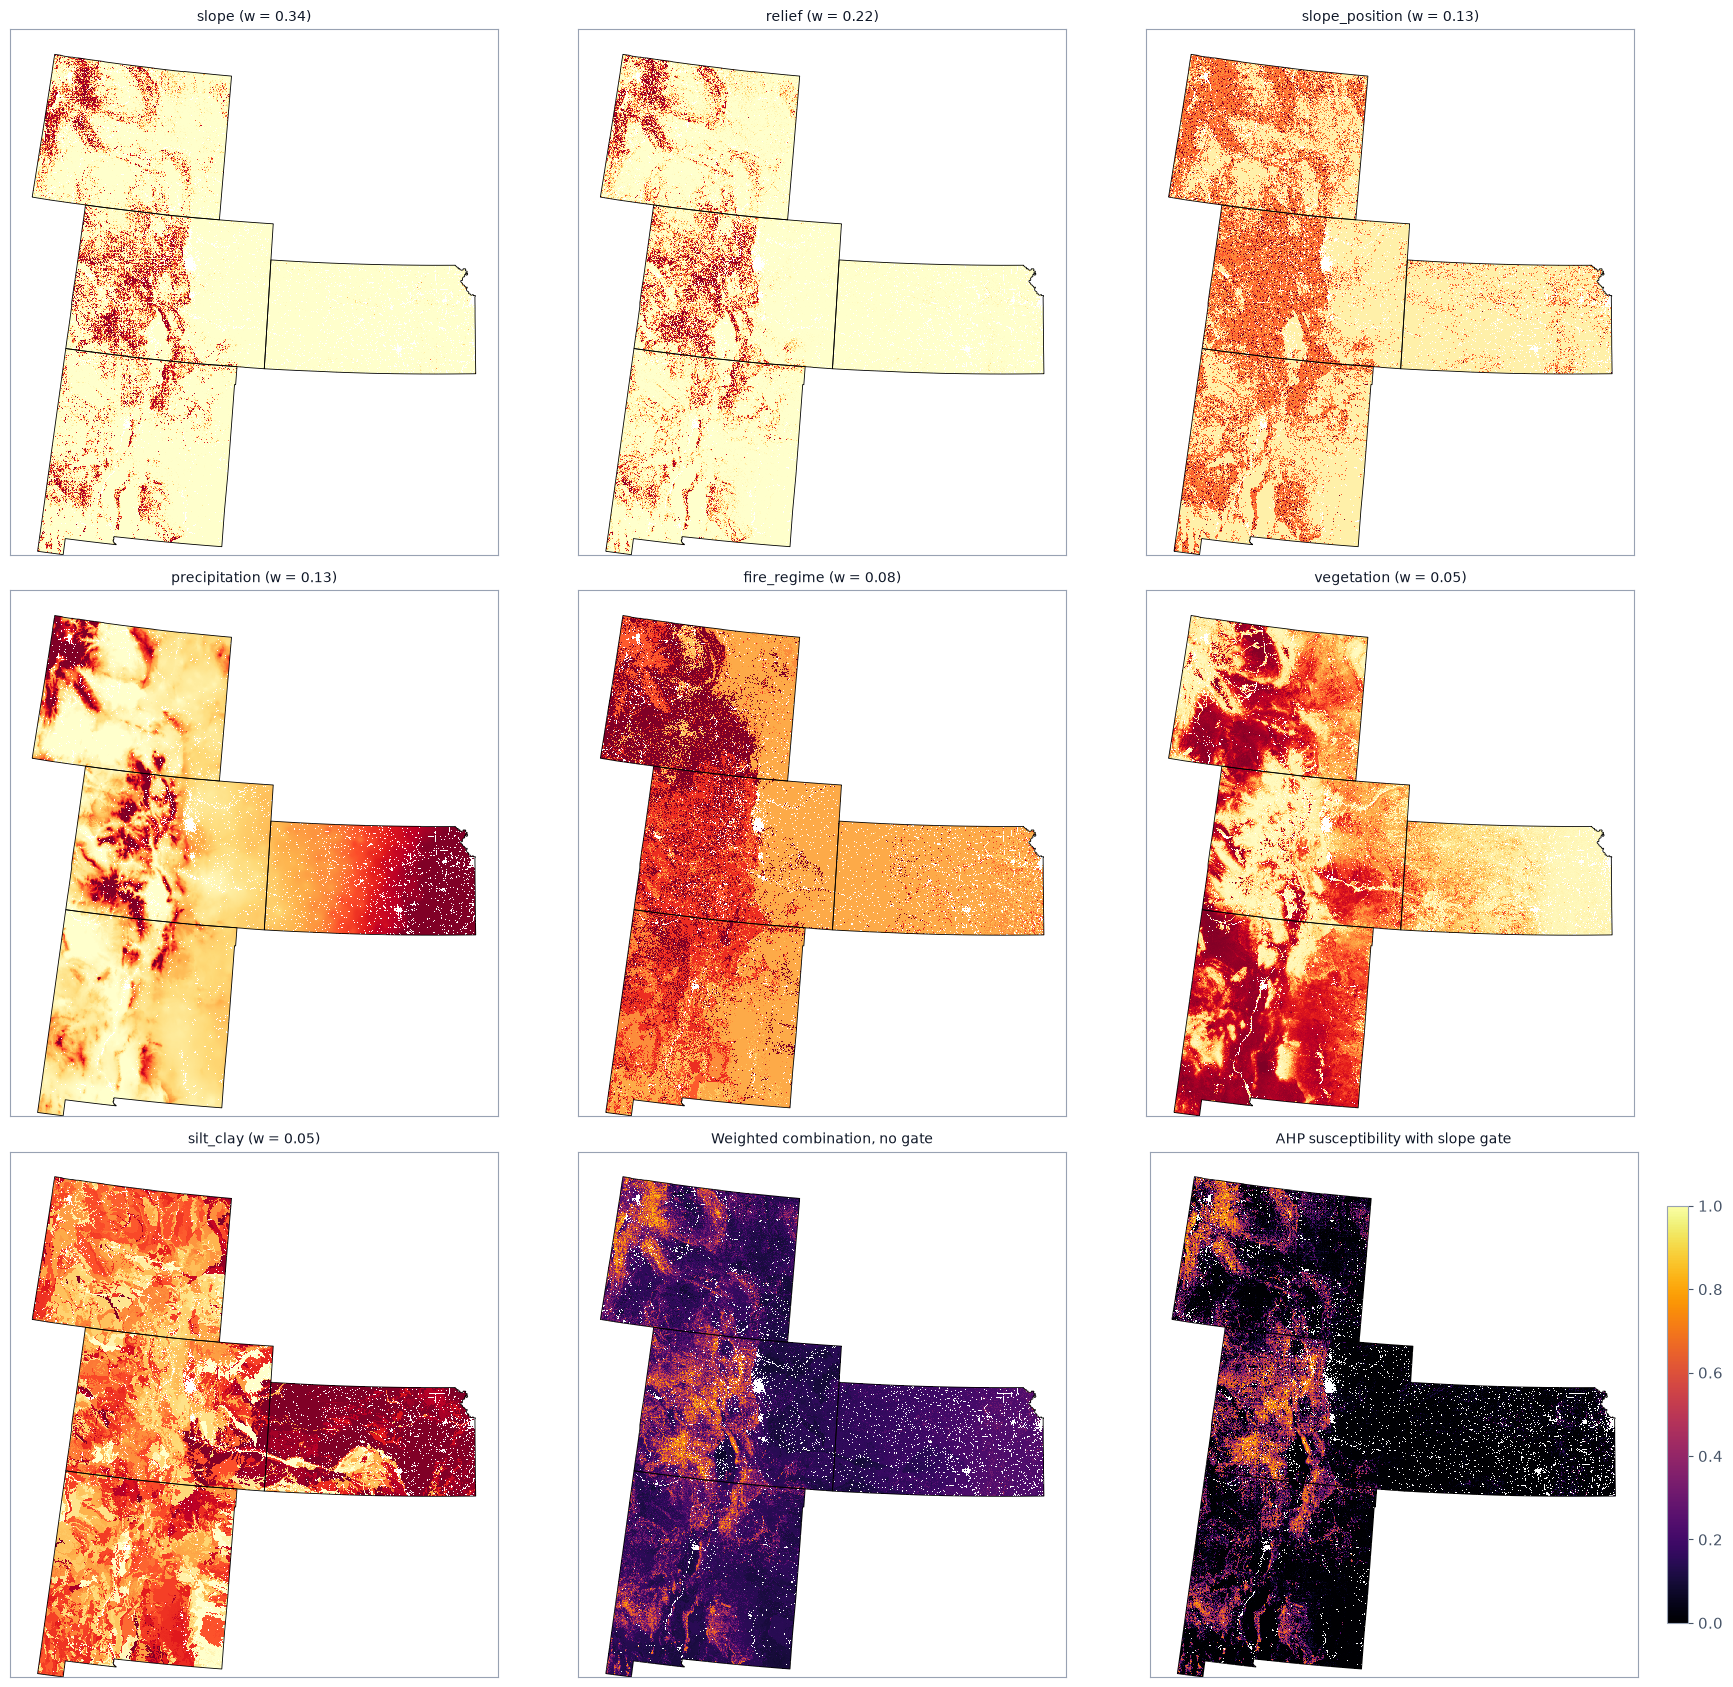

In [9]:
frg_score = {1: 0.5, 2: 0.4, 3: 0.7, 4: 1.0, 5: 0.6, 111: 0.0, 112: 0.3, 131: 0.7, 132: 0.5, 133: 0.3}
pos_score = {1: 0.6, 2: 0.1, 3: 1.0, 4: 0.5}
MEMBERS = {
    "slope": large(np.maximum(grid.slope_g.values, 1e-3), midpoint=15.0, spread=4.0),
    "relief": large(np.maximum(np.abs(grid.tpi_2000.values), 1e-3), midpoint=60.0, spread=3.0),
    "slope_position": grid.topo_2000.map(pos_score).values,
    "precipitation": linear(grid.preci.values, 250.0, 900.0),
    "fire_regime": grid.frg.map(frg_score).fillna(0.3).values,
    "vegetation": small(np.maximum(grid.ndvi.values, 0.01), midpoint=0.35, spread=4.0),
    "silt_clay": linear(grid.silt_clay.values, 20.0, 80.0),
}
MEMBERS = {k: np.clip(np.asarray(v, float), 0, 1) for k, v in MEMBERS.items()}
wlc = weighted_linear_combination(MEMBERS, W_AHP.to_dict())
# Non-compensatory slope gate: 0 below 2 degrees, rising to 1 at 8 degrees.
SLOPE_GATE = np.clip(linear(grid.slope_g.values, 2.0, 8.0), 0, 1)
grid["mcda_wlc"] = wlc
grid["mcda"] = wlc * SLOPE_GATE
print(f"Share of cells closed by the slope gate (< 2 deg): {np.mean(SLOPE_GATE == 0):.0%}")

fig, axes = plt.subplots(3, 3, figsize=(18, 17))
for ax, k in zip(axes.ravel(), CRITERIA):
    im = show(ax, MEMBERS[k], f"{k} (w = {W_AHP[k]:.2f})", "YlOrRd", vmin=0, vmax=1)
show(axes.ravel()[7], grid.mcda_wlc, "Weighted combination, no gate", "inferno", vmin=0, vmax=1)
im = show(axes.ravel()[8], grid.mcda, "AHP susceptibility with slope gate", "inferno", vmin=0, vmax=1)
plt.colorbar(im, ax=axes.ravel()[8], fraction=0.035)
plt.tight_layout()
plt.show()

## Model 3: machine learning

### Predictors

The predictors are the covariates of Ahmed et al. (2017). Aspect is turned into northness ($\cos$) and eastness ($\sin$) so that 359° and 1° are neighbours; flat cells get 0 for both. Slope length is log-transformed. The three categorical layers (slope position, land cover, fire regime) are one-hot encoded.

The paper reports strong correlation between elevation, temperature, precipitation and NDVI. As in the paper, all are kept: tree ensembles handle correlated predictors, and the logistic model is used only as a reference.

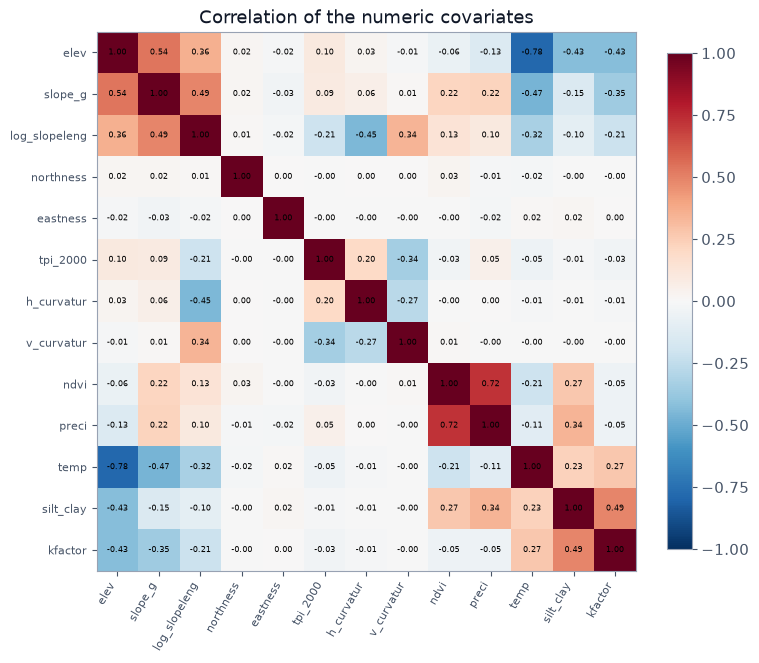

In [10]:
asp = np.radians(grid.aspect.clip(lower=0).values)
flat = grid.aspect.values < 0
X_num = pd.DataFrame({
    "elev": grid.elev, "slope_g": grid.slope_g, "log_slopeleng": np.log1p(grid.slopeleng),
    "northness": np.where(flat, 0, np.cos(asp)), "eastness": np.where(flat, 0, np.sin(asp)),
    "tpi_2000": grid.tpi_2000, "h_curvatur": grid.h_curvatur, "v_curvatur": grid.v_curvatur,
    "ndvi": grid.ndvi, "preci": grid.preci, "temp": grid.temp, "silt_clay": grid.silt_clay, "kfactor": grid.kfactor,
})
frg_group = grid.frg.where(grid.frg <= 5, 9).astype(int)  # FRG I-V, and 9 = no fire regime
X_cat = pd.concat([
    pd.get_dummies(grid.topo_2000.map(slope_pos_names), prefix="pos"),
    pd.get_dummies(grid.nlcd.map(nlcd_names), prefix="lc"),
    pd.get_dummies(frg_group.map({1: "I", 2: "II", 3: "III", 4: "IV", 5: "V", 9: "none"}), prefix="frg"),
], axis=1).astype(float)
X = pd.concat([X_num, X_cat], axis=1)
FEATURES = list(X.columns)
XA = X.values.astype(np.float32)
y_all = grid.landslide.values

corr = X_num.corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Correlation of the numeric covariates")
plt.show()

### Spatial cross-validation

Landslides cluster, so a random split puts near-identical neighbours in training and test sets and inflates the scores. Here folds are **100 km blocks**: a model is always tested on blocks it never saw. Each of the five negative draws is cross-validated, and out-of-fold predictions are kept for validation in Section 10.

Cross-validation: 105 scores in 78 s


AUC           TSS       
                   mean    std   mean    std
model                                       
RandomForest      0.915  0.026  0.692  0.063
GradientBoosting  0.915  0.028  0.688  0.064
Logistic          0.867  0.037  0.604  0.072
FrequencyRatio    0.824  0.064  0.525  0.080
AHP-MCDA          0.790  0.001  0.468  0.002

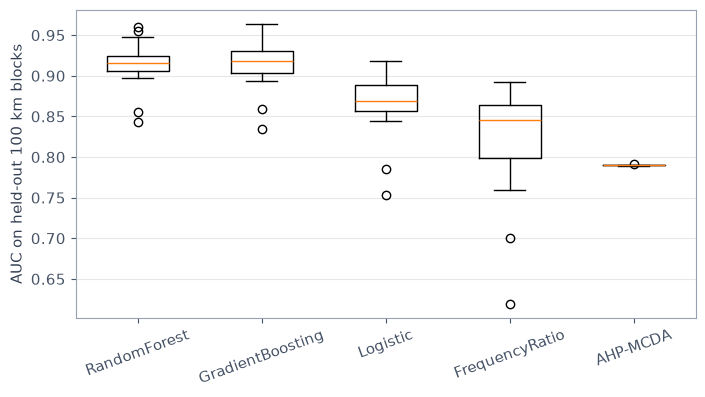

In [11]:
def make_models():
    return {
        "Logistic": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
        "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features="sqrt",
                                               n_jobs=-1, random_state=1),
        "GradientBoosting": HistGradientBoostingClassifier(max_depth=6, learning_rate=0.08, max_iter=250,
                                                           random_state=1),
    }


def tss_max(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


MODEL_NAMES = list(make_models())
oof = {m: np.full((N_DRAWS, len(grid)), np.nan) for m in MODEL_NAMES}  # out-of-fold predictions
oof_fr = np.full((N_DRAWS, len(grid)), np.nan)  # frequency ratio, refitted on training folds
rows = []
t0 = time.time()
for d, neg in enumerate(neg_draws):
    idx = np.r_[pres_idx, neg]
    y = y_all[idx]
    groups = grid.block.values[idx]
    for k, (tr, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(idx, y, groups)):
        if y[te].sum() == 0 or y[tr].sum() == 0:
            continue
        for name, model in make_models().items():
            p = model.fit(XA[idx[tr]], y[tr]).predict_proba(XA[idx[te]])[:, 1]
            oof[name][d, idx[te]] = p
            rows.append((d, k, name, roc_auc_score(y[te], p), tss_max(y[te], p)))
        # Frequency ratio from the training blocks only.
        train_mask = ~np.isin(grid.block.values, np.unique(groups[te]))
        p_fr = lsi(fr_tables(train_mask), idx[te])
        oof_fr[d, idx[te]] = p_fr
        rows.append((d, k, "FrequencyRatio", roc_auc_score(y[te], p_fr), tss_max(y[te], p_fr)))
    # The AHP model uses no training data: score it on the same test rows.
    rows.append((d, -1, "AHP-MCDA", roc_auc_score(y, grid.mcda.values[idx]), tss_max(y, grid.mcda.values[idx])))
cv = pd.DataFrame(rows, columns=["draw", "fold", "model", "AUC", "TSS"])
print(f"Cross-validation: {len(cv)} scores in {time.time() - t0:.0f} s")

perf = cv.groupby("model")[["AUC", "TSS"]].agg(["mean", "std"]).sort_values(("AUC", "mean"), ascending=False)
display(perf.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
order = perf.index.tolist()
ax.boxplot([cv[(cv.model == m) & (cv.fold >= 0)].AUC if m != "AHP-MCDA" else cv[cv.model == m].AUC for m in order])
ax.set_xticks(range(1, len(order) + 1), order)
ax.set_ylabel("AUC on held-out 100 km blocks")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=20)
plt.show()

**Reading the cross-validation.** The fold-to-fold spread is as informative as the mean. Blocks differ in landform, climate and, above all, in how they were mapped, so a model that does well on average can still miss whole regions. The AHP model's AUC is computed on all sampled cells because it was never fitted; it is directly comparable with the held-out scores of the other models.

### Final models and susceptibility maps

Each machine-learning model is refitted on all data for every negative draw and applied to all 1 million cells; the five predictions are averaged. The random forest, the method of Ahmed et al. (2017), is the headline model; gradient boosting and logistic regression are kept for comparison.

Final fits and predictions in 24 s


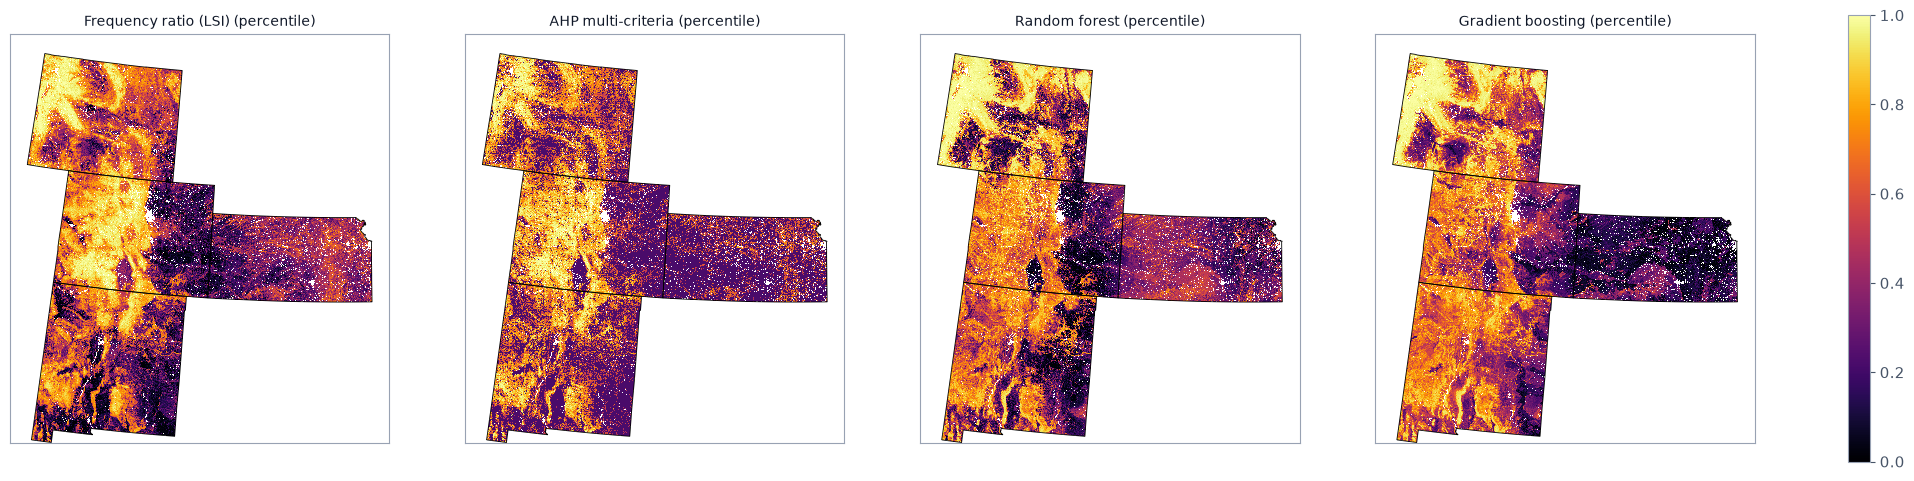

,fr_lsi,mcda,p_RandomForest,p_GradientBoosting,p_Logistic
fr_lsi,1.00,0.82,0.81,0.70,0.74
mcda,0.82,1.00,0.72,0.66,0.54
p_RandomForest,0.81,0.72,1.00,0.82,0.59
p_GradientBoosting,0.70,0.66,0.82,1.00,0.37
p_Logistic,0.74,0.54,0.59,0.37,1.00


In [12]:
t0 = time.time()
pred = {name: np.zeros(len(grid)) for name in MODEL_NAMES}
rf_draws = []  # random-forest predictions per draw, for the uncertainty map
fitted_rf = []
for d, neg in enumerate(neg_draws):
    idx = np.r_[pres_idx, neg]
    for name, model in make_models().items():
        if name == "RandomForest":
            model.set_params(n_estimators=150)
        model.fit(XA[idx], y_all[idx])
        p = model.predict_proba(XA)[:, 1]
        pred[name] += p / N_DRAWS
        if name == "RandomForest":
            rf_draws.append(p.astype(np.float32))
            if d == 0:
                fitted_rf.append((model, idx))
for name in MODEL_NAMES:
    grid[f"p_{name}"] = pred[name]
print(f"Final fits and predictions in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 4, figsize=(24, 8))
maps = [("fr_lsi", "Frequency ratio (LSI)"), ("mcda", "AHP multi-criteria"),
        ("p_RandomForest", "Random forest"), ("p_GradientBoosting", "Gradient boosting")]
for ax, (col, title) in zip(axes, maps):
    v = grid[col].rank(pct=True)  # percentile rank puts all four on one scale
    im = show(ax, v, f"{title} (percentile)", "inferno", vmin=0, vmax=1)
plt.colorbar(im, ax=axes, fraction=0.012)
plt.show()

rank_corr = grid[[c for c, _ in maps] + ["p_Logistic"]].corr(method="spearman")
display(rank_corr.round(2))

**Comparing the maps.** Percentile ranks put the four models on one scale. Expect broad agreement on the extremes: the mountain ranges high, the High Plains low. The Spearman table shows how far the rankings agree overall; the interesting differences usually lie at intermediate elevations, where rules of thumb (Model 2) and the inventory (Models 1 and 3) can disagree about moderately steep, dry slopes.

## What drives susceptibility?

**Permutation importance** measures how much the held-out AUC of the random forest falls when one predictor is shuffled. One-hot columns of the same layer are shuffled together so that each layer is judged as a whole. **Partial dependence** shows the average modelled response to one predictor, as Ahmed et al. (2017) did for soil carbon.

Held-out AUC of this fit: 0.959


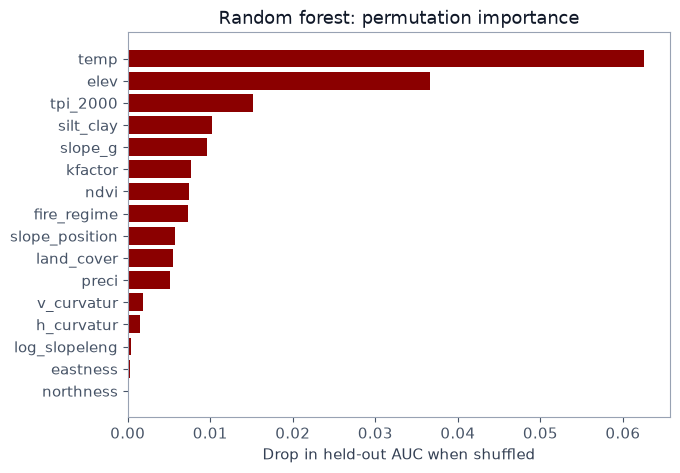

In [13]:
model, idx_fit = fitted_rf[0]
# Use a held-out block set: refit on four folds, score the fifth.
idx = np.r_[pres_idx, neg_draws[0]]
groups = grid.block.values[idx]
tr, te = next(GroupKFold(n_splits=N_FOLDS).split(idx, y_all[idx], groups))
rf_imp = make_models()["RandomForest"].fit(XA[idx[tr]], y_all[idx[tr]])
layers_of = {c: c for c in X_num.columns}
layers_of.update({c: "slope_position" for c in X_cat.columns if c.startswith("pos_")})
layers_of.update({c: "land_cover" for c in X_cat.columns if c.startswith("lc_")})
layers_of.update({c: "fire_regime" for c in X_cat.columns if c.startswith("frg_")})
Xte, yte = XA[idx[te]].copy(), y_all[idx[te]]
base = roc_auc_score(yte, rf_imp.predict_proba(Xte)[:, 1])
imp = {}
for layer in dict.fromkeys(layers_of.values()):
    cols = [FEATURES.index(c) for c, l in layers_of.items() if l == layer]
    drops = []
    for rep in range(3):
        Xp = Xte.copy()
        perm = RNG.permutation(len(Xp))
        Xp[:, cols] = Xp[perm][:, cols]
        drops.append(base - roc_auc_score(yte, rf_imp.predict_proba(Xp)[:, 1]))
    imp[layer] = np.mean(drops)
imp = pd.Series(imp).sort_values(ascending=False)
print(f"Held-out AUC of this fit: {base:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color="darkred")
ax.set_xlabel("Drop in held-out AUC when shuffled")
ax.set_title("Random forest: permutation importance")
plt.show()

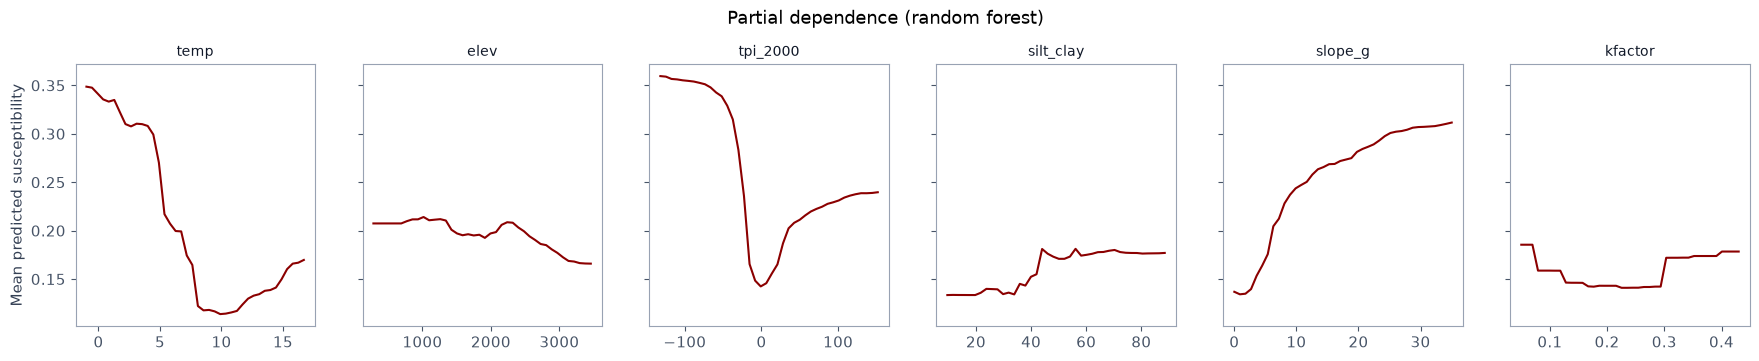

In [14]:
top = [c for c in imp.index if c in X_num.columns][:6]
fig, axes = plt.subplots(1, len(top), figsize=(3.6 * len(top), 3.4), sharey=True)
sample = XA[RNG.choice(len(grid), 4000, replace=False)]
for ax, name in zip(axes, top):
    j = FEATURES.index(name)
    xs = np.linspace(*np.nanpercentile(XA[:, j], [1, 99]), 40)
    resp = []
    for v in xs:
        Xs = sample.copy()
        Xs[:, j] = v
        resp.append(model.predict_proba(Xs)[:, 1].mean())
    ax.plot(xs, resp, color="darkred")
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("Mean predicted susceptibility")
plt.suptitle("Partial dependence (random forest)", y=1.04)
plt.show()

Compare the ranking with Table 1 and Figure 5 of Ahmed et al. (2017). There, NDVI, precipitation, temperature and elevation explained soil carbon; here the terrain variables should dominate, because landslides are a mechanical process. Where climate and vegetation still rank high, they act largely as stand-ins for the mountain environment, and partly for where inventories were compiled (Section 13).

## Validation of all models

Two curves are standard in landslide studies (Chung and Fabbri 2003):

- the **success-rate curve** uses the landslides the model was fitted on and measures goodness of fit;
- the **prediction-rate curve** uses landslides the model did not see and measures predictive skill.

Cells are ranked from most to least susceptible; the curve plots the cumulative share of landslide cells against the cumulative share of area. A curve that rises steeply means a small fraction of the land captures most landslides. The area under the prediction-rate curve is the headline comparison.

Prediction-rate curves use out-of-fold predictions (averaged over draws) and are computed within surveyed tiles, where absence of a record means something.

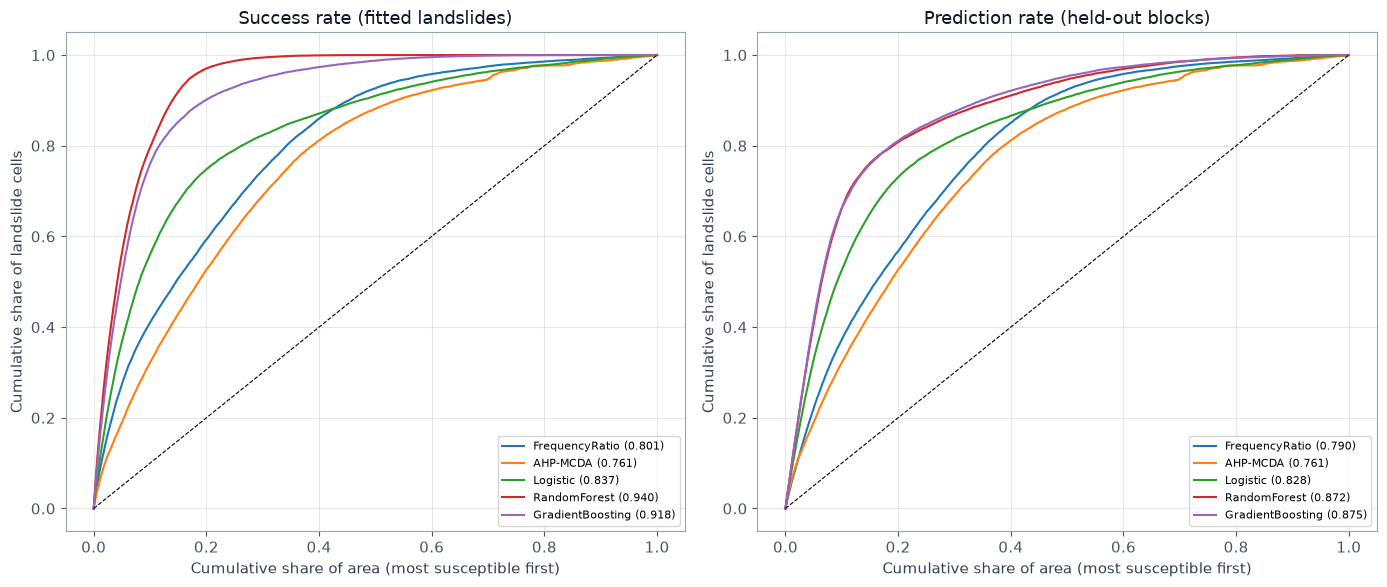

,success_rate_AUC,prediction_rate_AUC,overfit_gap
model,,,
FrequencyRatio,0.801,0.790,0.011
AHP-MCDA,0.761,0.761,0.000
Logistic,0.837,0.828,0.009
RandomForest,0.940,0.872,0.068
GradientBoosting,0.918,0.875,0.043


In [15]:
def rate_curve(score, mask):
    """Cumulative share of landslide cells vs cumulative share of area, ranked by score."""
    s, y = score[mask], y_all[mask]
    order = np.argsort(-s, kind="stable")
    cum_ls = np.cumsum(y[order]) / y.sum()
    cum_area = np.arange(1, len(s) + 1) / len(s)
    return cum_area, cum_ls, float(np.trapezoid(cum_ls, cum_area))


surveyed = grid.surveyed.values
oof_mean = {m: np.nanmean(oof[m], axis=0) for m in MODEL_NAMES}
oof_mean["FrequencyRatio"] = np.nanmean(oof_fr, axis=0)
has_oof = np.isfinite(oof_mean["RandomForest"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
curves = []
for name, col in [("FrequencyRatio", "fr_lsi"), ("AHP-MCDA", "mcda"), ("Logistic", "p_Logistic"),
                  ("RandomForest", "p_RandomForest"), ("GradientBoosting", "p_GradientBoosting")]:
    a, l, auc_s = rate_curve(grid[col].values, surveyed)
    axes[0].plot(a, l, label=f"{name} ({auc_s:.3f})")
    if name == "AHP-MCDA":
        a2, l2, auc_p = a, l, auc_s  # never fitted: success = prediction
    else:
        m = surveyed & has_oof
        a2, l2, auc_p = rate_curve(np.nan_to_num(oof_mean[name], nan=-np.inf), m)
    axes[1].plot(a2, l2, label=f"{name} ({auc_p:.3f})")
    curves.append({"model": name, "success_rate_AUC": auc_s, "prediction_rate_AUC": auc_p})
for ax, title in zip(axes, ["Success rate (fitted landslides)", "Prediction rate (held-out blocks)"]):
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("Cumulative share of area (most susceptible first)")
    ax.set_ylabel("Cumulative share of landslide cells")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
curves = pd.DataFrame(curves).set_index("model")
curves["overfit_gap"] = curves.success_rate_AUC - curves.prediction_rate_AUC
display(curves.round(3))

**Reading the curves.** The gap between success and prediction rate (`overfit_gap`) is a direct measure of over-fitting. Flexible models fit the training landslides almost perfectly, so their success-rate curves hug the top-left corner; what matters is how much of that survives on unseen blocks. The AHP model has no gap by construction, and its prediction-rate area is the bar the data-driven models must clear to justify their complexity.

## Susceptibility classes

Planners use classes, not continuous scores. Classes are set by **share of area**, so that each model's classes cover the same land and can be compared directly: very low (lowest 50 %), low (next 20 %), moderate (next 15 %), high (next 10 %) and very high (top 5 %). A good map concentrates landslides in the upper classes, so the **landslide density** should rise steadily from class to class.

In [16]:
CLASS_NAMES = ["very low", "low", "moderate", "high", "very high"]
CLASS_CUTS = [0.50, 0.70, 0.85, 0.95]


def classify(score):
    q = np.nanquantile(score, CLASS_CUTS)
    return np.searchsorted(q, score, side="right")


rows = []
for name, col in [("FrequencyRatio", "fr_lsi"), ("AHP-MCDA", "mcda"), ("RandomForest", "p_RandomForest"),
                  ("GradientBoosting", "p_GradientBoosting")]:
    cls = classify(grid[col].values)
    grid[f"class_{name}"] = cls
    for k, cname in enumerate(CLASS_NAMES):
        m = surveyed & (cls == k)
        rows.append({"model": name, "class": cname, "share_of_landslide_cells_%": 100 * y_all[m].sum() / y_all[surveyed].sum(),
                     "landslide_density_per_1000_km2": 1000 * y_all[m].sum() / max(m.sum(), 1)})
cls_tab = pd.DataFrame(rows)
display(cls_tab.pivot(index="class", columns="model", values="share_of_landslide_cells_%").reindex(CLASS_NAMES).round(1)
        .rename_axis(columns="% of landslide cells"))
display(cls_tab.pivot(index="class", columns="model", values="landslide_density_per_1000_km2").reindex(CLASS_NAMES).round(1)
        .rename_axis(columns="landslide cells per 1000 km2"))

% of landslide cells,AHP-MCDA,FrequencyRatio,GradientBoosting,RandomForest
class,,,,
very low,6.5,3.1,0.1,0.0
low,9.6,7.7,1.9,0.0
moderate,27.0,25.8,6.4,2.0
high,30.8,28.1,25.1,27.3
very high,26.1,35.4,66.5,70.7


landslide cells per 1000 km2,AHP-MCDA,FrequencyRatio,GradientBoosting,RandomForest
class,,,,
very low,6.6,3.3,0.1,0.0
low,15.9,12.4,2.5,0.1
moderate,45.9,42.6,10.4,3.3
high,73.3,66.4,60.7,66.1
very high,123.3,166.4,313.6,332.9


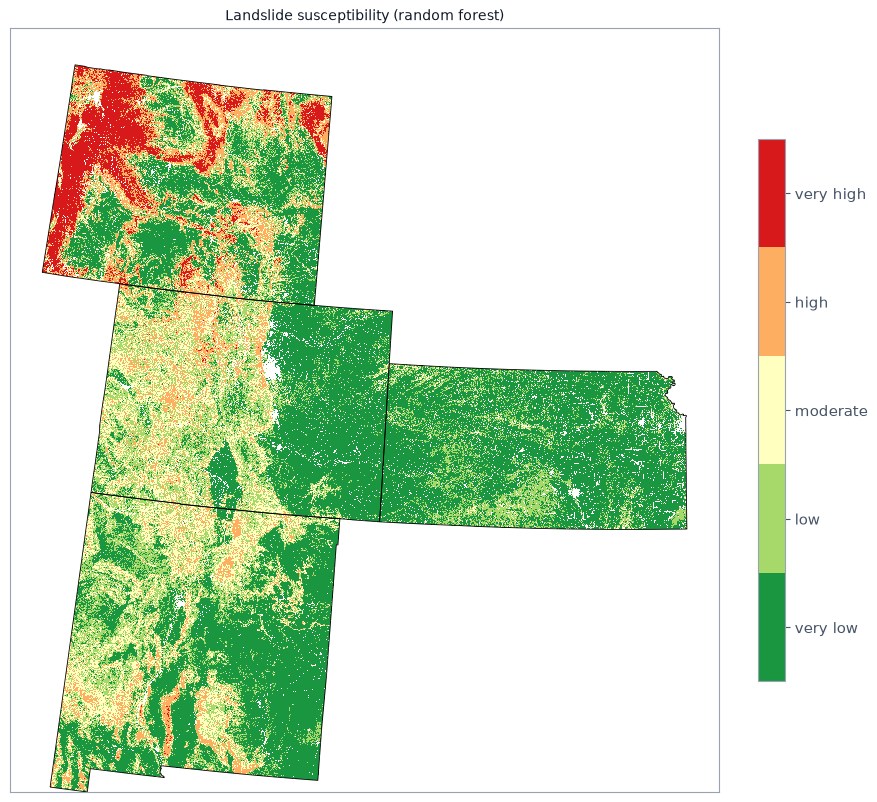

% of state area (random forest),very low,low,moderate,high,very high
state,,,,,
Colorado,44.7,23.5,21.8,9.8,0.1
Kansas,79.2,18.9,1.9,0.0,0.0
New Mexico,48.6,23.2,20.2,7.9,0.1
Wyoming,33.8,13.1,11.9,20.9,20.4


% of land-cover area (random forest),very low,low,moderate,high,very high
nlcd,,,,,
Barren,36.8,11.5,23.2,21.2,7.2
Forest,8.8,30.7,34.1,16.6,9.8
Herbaceous,65.2,18.4,8.4,5.0,3.0
Planted/Cultivated,85.4,11.7,1.7,1.0,0.1
Shrubland,39.0,20.4,18.1,15.6,6.9


In [17]:
cmap5 = plt.matplotlib.colors.ListedColormap(["#1a9641", "#a6d96a", "#ffffbf", "#fdae61", "#d7191c"])
fig, ax = plt.subplots(figsize=(10, 11))
im = show(ax, grid.class_RandomForest, "Landslide susceptibility (random forest)", cmap5, vmin=-0.5, vmax=4.5)
cb = plt.colorbar(im, ax=ax, fraction=0.035, ticks=range(5))
cb.ax.set_yticklabels(CLASS_NAMES)
plt.show()

area_state = (pd.crosstab(grid.state, grid.class_RandomForest.map(dict(enumerate(CLASS_NAMES))), normalize="index") * 100)
display(area_state[CLASS_NAMES].round(1).rename_axis(columns="% of state area (random forest)"))
area_lc = (pd.crosstab(grid.nlcd.map(nlcd_names), grid.class_RandomForest.map(dict(enumerate(CLASS_NAMES))), normalize="index") * 100)
display(area_lc[CLASS_NAMES].round(1).rename_axis(columns="% of land-cover area (random forest)"))

## Uncertainty

Two sources of uncertainty are quantified:

- **Training sample (Model 3).** Each negative draw gives a slightly different random forest. The standard deviation across the five draws shows where the map depends on which negatives were chosen.
- **Weights (Model 2).** `monte_carlo_weights` draws 500 weight vectors from a Dirichlet distribution around the AHP weights and reports the spread of the score and how often each cell stays in the top 10 percent.

Monte Carlo weights in 43 s; median Jaccard of top-10 % sets vs AHP baseline 0.90


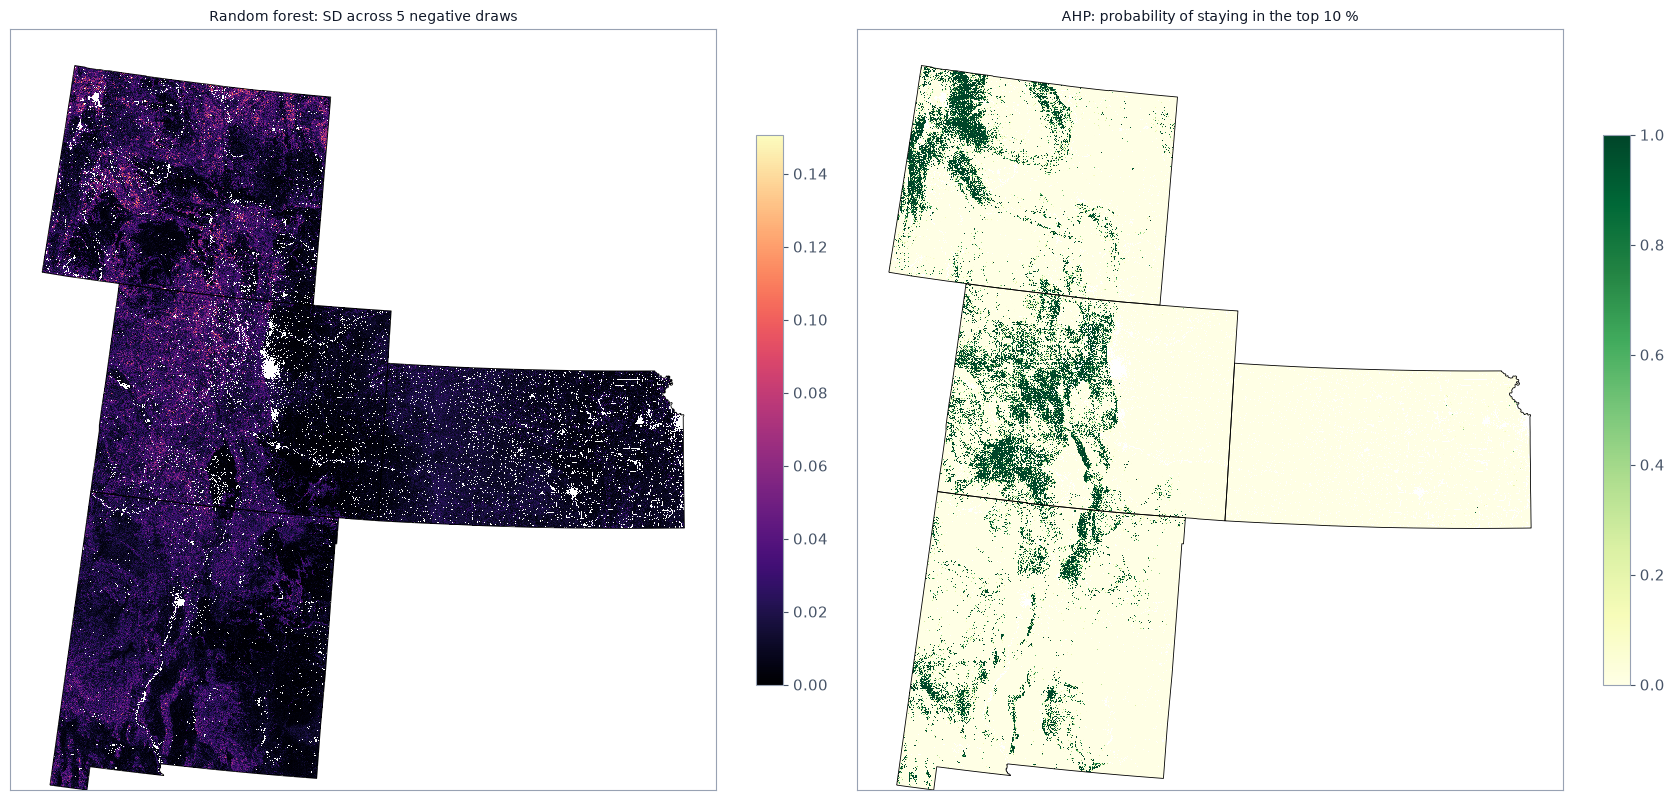

Agreement of 'very high' classes (Jaccard):


,Jaccard
RF vs AHP,0.16
RF vs FR,0.30
AHP vs FR,0.35


In [18]:
rf_sd = np.std(np.vstack(rf_draws), axis=0)
M = np.stack([MEMBERS[k] for k in CRITERIA])
t0 = time.time()
M = M * SLOPE_GATE  # apply the gate to every criterion so the weighted sum equals the gated score
mc = monte_carlo_weights(M, W_AHP.values, kappa=50.0, n=500, batch=25, top_q=0.9, seed=11)
print(f"Monte Carlo weights in {time.time() - t0:.0f} s; median Jaccard of top-10 % sets vs AHP baseline "
      f"{np.median(mc['jaccard']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 8))
im0 = show(axes[0], rf_sd, "Random forest: SD across 5 negative draws", "magma")
plt.colorbar(im0, ax=axes[0], fraction=0.035)
im1 = show(axes[1], mc["p_top"], "AHP: probability of staying in the top 10 %", "YlGn", vmin=0, vmax=1)
plt.colorbar(im1, ax=axes[1], fraction=0.035)
plt.tight_layout()
plt.show()

top_rf = grid.class_RandomForest.values == 4
top_mcda = grid["class_AHP-MCDA"].values == 4
top_fr = grid.class_FrequencyRatio.values == 4
print("Agreement of 'very high' classes (Jaccard):")
display(pd.Series({"RF vs AHP": jaccard_index(top_rf, top_mcda), "RF vs FR": jaccard_index(top_rf, top_fr),
                   "AHP vs FR": jaccard_index(top_mcda, top_fr)}).round(2).to_frame("Jaccard"))
grid["n_models_very_high"] = top_rf.astype(int) + top_mcda.astype(int) + top_fr.astype(int)

The Jaccard values show how much the "very high" classes of the three model families overlap; 1 would mean identical sets. Cells rated very high by all three are the most defensible priorities; cells rated very high by only one deserve a second look before they drive a decision.

## Where the inventory is likely incomplete

A susceptibility model can also audit its own training data. Kansas is the natural first check: if most of its high-susceptibility land lies in unsurveyed tiles, the low landslide count there says more about mapping than about stability. Cells the random forest rates **high or very high** but that lie in **unsurveyed tiles** are places where landslides are probably present but not recorded. Summarising them by state shows where new mapping would add most to the national inventory.

,high_or_very_high_km2,in_unsurveyed_tiles_km2,share_unsurveyed_%
state,,,
Colorado,25652,19,0.074
Kansas,65,63,96.923
New Mexico,24814,227,0.915
Wyoming,100857,2702,2.679


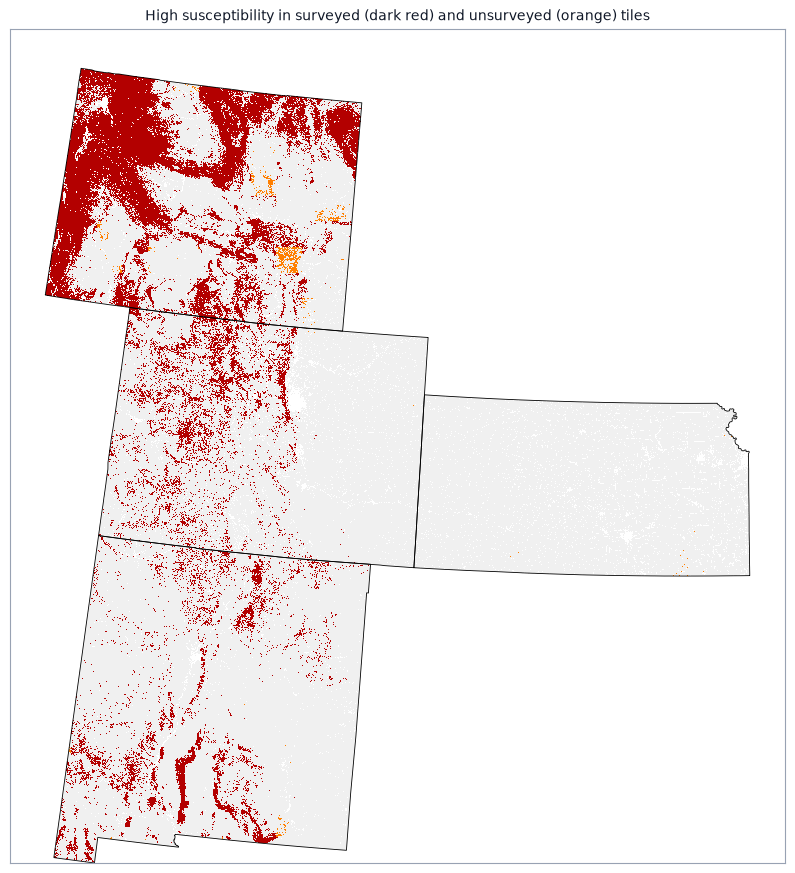

In [19]:
high = grid.class_RandomForest.values >= 3
gap = pd.DataFrame({
    "high_or_very_high_km2": grid[high].groupby("state").size(),
    "in_unsurveyed_tiles_km2": grid[high & ~surveyed].groupby("state").size(),
}).fillna(0).astype(int)
gap["share_unsurveyed_%"] = 100 * gap.in_unsurveyed_tiles_km2 / gap.high_or_very_high_km2.clip(lower=1)
display(gap)

fig, ax = plt.subplots(figsize=(10, 11))
cat = np.where(high & surveyed, 2.0, np.where(high & ~surveyed, 1.0, np.where(surveyed, 0.3, 0.0)))
cm = plt.matplotlib.colors.ListedColormap(["#f0f0f0", "#cccccc", "#ff7f00", "#b30000"])
show(ax, cat, "High susceptibility in surveyed (dark red) and unsurveyed (orange) tiles", cm, vmin=-0.1, vmax=2.1)
plt.show()

## Outputs

In [20]:
def save(name, values):
    arr = to_raster(values)
    return write_raster_data(OUT / name, np.where(np.isfinite(arr), arr, -9999).astype("float32"), crs=CRS.to_wkt(),
                             geotransform=GT, nodata=-9999.0, overwrite=True)


for name, col in [("susceptibility_rf_1km.tif", "p_RandomForest"), ("susceptibility_gbm_1km.tif", "p_GradientBoosting"),
                  ("susceptibility_logistic_1km.tif", "p_Logistic"), ("susceptibility_fr_lsi_1km.tif", "fr_lsi"),
                  ("susceptibility_ahp_1km.tif", "mcda"), ("class_rf_1km.tif", "class_RandomForest"),
                  ("models_agreeing_very_high_1km.tif", "n_models_very_high")]:
    save(name, grid[col])
save("rf_sd_across_draws_1km.tif", rf_sd)
save("ahp_p_top10_1km.tif", mc["p_top"])

cv.to_csv(OUT / "cross_validation_scores.csv", index=False)
curves.to_csv(OUT / "success_prediction_rate_auc.csv")
imp.rename("auc_drop").to_csv(OUT / "rf_permutation_importance.csv")
pd.concat({f: t for f, t in fr_all.items()}).rename("frequency_ratio").to_csv(OUT / "frequency_ratios.csv")
W_AHP.rename("weight").to_csv(OUT / "ahp_weights.csv")
pts[["confidence", "STATE", "geometry"] + ([src_col] if src_col else [])].to_file(
    OUT / "landslide_records_four_states.gpkg", driver="GPKG")

for p in sorted(OUT.glob("*")):
    print(f"  {p.name:42s} {p.stat().st_size / 1024:9.1f} KB")

  ahp_p_top10_1km.tif                           8310.3 KB
  ahp_weights.csv                                  0.2 KB
  class_rf_1km.tif                              8310.3 KB
  cross_validation_scores.csv                      5.7 KB
  frequency_ratios.csv                             3.2 KB
  landslide_records_four_states.gpkg            8084.0 KB
  models_agreeing_very_high_1km.tif             8310.3 KB
  rf_permutation_importance.csv                    0.5 KB
  rf_sd_across_draws_1km.tif                    8310.3 KB
  success_prediction_rate_auc.csv                  0.4 KB
  susceptibility_ahp_1km.tif                    8310.3 KB
  susceptibility_fr_lsi_1km.tif                 8310.3 KB
  susceptibility_gbm_1km.tif                    8310.3 KB
  susceptibility_logistic_1km.tif               8310.3 KB
  susceptibility_rf_1km.tif                     8310.3 KB


## Limitations

- **Inventory heterogeneity.** The national compilation joins inventories of very different scope, date and method. The surveyed-tile background reduces the bias this causes, but cannot remove it: a tile with one mapped landslide counts as surveyed even if most of it was never examined.
- **Resolution.** A 1 km node carries the 90 m slope at one point. Landslides start on slopes a few tens of metres across, so the map is a regional screen. Site decisions need 10 m terrain and field mapping; the USGS national susceptibility map (Mirus et al. 2024) works at about 10 m.
- **Mixed landslide types.** Rockfall, debris flows, shallow slides and deep-seated slides are modelled together. Their controls differ, and type-specific models would be sharper where the inventory's `LS_Type` field is filled.
- **Missing geology.** Lithology and structure strongly control deep-seated landslides in the Colorado Plateau and Wyoming basins, and are not among the covariates. Soil texture and land cover partly stand in for them.
- **Static covariates.** Fire regime describes historical fire, not recent burn scars. Post-fire debris-flow hazard changes year by year and is mapped separately by the USGS for individual fires.
- **Excluded land.** Developed land, water and wetlands are outside the grid, so landslides recorded in towns and along reservoirs do not enter the model.

## Where to go next

| If you want to... | Open |
|---|---|
| Revisit fuzzy memberships and weighted overlay | [`03_04_02_00_fuzzy_logic_foundations.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_02_00_fuzzy_logic_foundations.ipynb) |
| Explore weight uncertainty further | [`03_04_03_sensitivity_uncertainty.ipynb`](../03_04_multi_criteria_suitability_analysis/03_04_03_sensitivity_uncertainty.ipynb) |
| Compare with presence-background habitat modelling | [`03_08_05_habitat_suitability.ipynb`](03_08_05_habitat_suitability.ipynb) |
| Derive terrain covariates from a DEM | [`03_02_02_terrain_analysis.ipynb`](../03_02_digital_terrain_modeling/03_02_02_terrain_analysis.ipynb) |

### References

1. Ahmed, Z. U., Woodbury, P. B., Sanderman, J., Hawke, B., Jauss, V., Solomon, D., Lehmann, J. (2017). Assessing soil carbon vulnerability in the Western USA by geospatial modeling of pyrogenic and particulate carbon stocks. *Journal of Geophysical Research: Biogeosciences*, 122, 354-369. https://doi.org/10.1002/2016JG003488
2. Belair, G. M., Mirus, B. B., Luna, L. V., Jones, E. S. (2025). *Landslide Inventories across the United States* (ver. 3.0, February 2025). U.S. Geological Survey data release. https://doi.org/10.5066/P14AJF8I
3. Mirus, B. B., Jones, E. S., Baum, R. L., Godt, J. W., et al. (2020). Landslides across the USA: occurrence, susceptibility, and data limitations. *Landslides*, 17, 2271-2285.
4. Mirus, B. B., Belair, G. M., Wood, N. J., Jones, J. M., Martinez, S. N. (2024). Parsimonious high-resolution landslide susceptibility modeling at continental scales. *AGU Advances*, 5, e2024AV001214.
5. Saaty, T. L. (1980). *The Analytic Hierarchy Process*. McGraw-Hill.
6. Chung, C.-J. F., Fabbri, A. G. (2003). Validation of spatial prediction models for landslide hazard mapping. *Natural Hazards*, 30, 451-472.
7. Lee, S., Pradhan, B. (2007). Landslide hazard mapping at Selangor, Malaysia using frequency ratio and logistic regression models. *Landslides*, 4, 33-41.
8. Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5-32.